In [ ]:
!git clone https://github.com/chenandrewy/high-throughput-ap.git

Cloning into 'high-throughput-ap'...
remote: Enumerating objects: 130, done.
remote: Counting objects: 100% (130/130), done.
remote: Compressing objects: 100% (90/90), done.
remote: Total 130 (delta 70), reused 96 (delta 40), pack-reused 0 (from 0)
Receiving objects: 100% (130/130), 107.20 KiB | 17.87 MiB/s, done.
Resolving deltas: 100% (70/70), done.


In [ ]:
cd high-throughput-ap/

/content/high-throughput-ap


100%|██████████| 4/4 [01:15<00:00, 18.83s/it]


            # strategies  5 pctile  50 pctile  95 pctile
acct_ew           29,314      -7.0       -1.1        3.7
acct_vw           29,314      -4.5       -0.4        3.9
past_ret_ew       19,402      -5.3       -0.4        2.1
past_ret_vw       19,402      -3.4        0.1        4.3
ticker_ew         19,380      -0.9       -0.0        0.8
ticker_vw         19,380      -2.2       -0.2        1.6


TypeError: unsupported operand type(s) for /: 'str' and 'str'

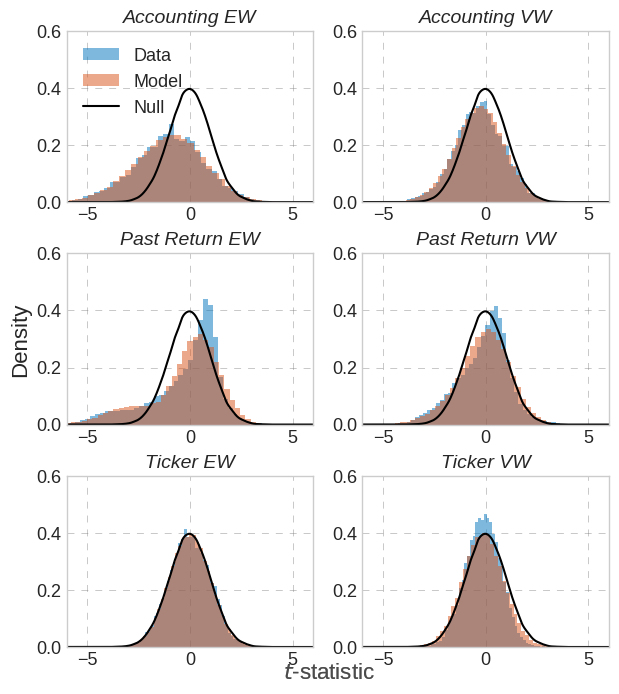

In [ ]:
# -*- coding: utf-8 -*-
"""
Created on Mon Feb  5 09:47:28 2024

@author: cdim
"""


import os, re, platform
import pandas as pd
import numpy as np
from tqdm import tqdm
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import seaborn as sns
import statsmodels.formula.api as smf
from scipy.stats import norm
from pathlib import Path
from sklearn.mixture import GaussianMixture
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster, ClusterWarning
from joblib import Parallel, delayed
from multiprocessing import Pool, cpu_count
from functools import partial
import warnings
import inspect
import string
from glob import glob


warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action="ignore", category=ClusterWarning)


tqdm.monitor_interval = 0
tqdm.pandas()
idx = pd.IndexSlice

CPUUsed = cpu_count()-1

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({"font.size": 13})
# COLORS = plt.rcParams['axes.prop_cycle'].by_key()['color']
COLORS = ['#0072BD', '#D95319', '#EDB120', '#7E2F8E',
          '#77AC30', '#4DBEEE', '#A2142F']




# Get the directory of the current file
# current_filename = inspect.getframeinfo(inspect.currentframe()).filename
# current_directory = os.path.dirname(current_filename)
# path_root = Path(current_directory + "/../../")
path_input = Path('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/')
path_output = Path('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/')
path_root = '/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/hight_throughput_output/'


#%%

path_figs = path_root + "figures/"
path_tables = path_root + "tables/"

# # set directories for user
# MachineUsed = platform.node()
# if MachineUsed == 'GWSB-DUQ456-L30':  # Chuks

# else:  # Andrew
#     path_input = path_root / "Data/"
#     path_output = path_root / "Data/"
#     path_figs = path_root / "Andrew/Figures/"
#     path_tables = path_root / "Andrew/Tables/"


# Select rolling t-stat / oos file
# estimates_file = "ChuksDebug_Predict_SignalYear.csv.gzip"
# rollsignal_file = "OOS_signal_tstat_OosNyears1.csv.gzip"
estimates_file = 'Nelly_Predict_SignalYear.csv.gzip'
rollsignal_file = 'OOS_signal_tstat_OosNyears1.csv.gzip'


SIGNAL_FAMILY_NAME_MAP = {
    "DataMinedLongShortReturnsEW": "acct_ew",
    "DataMinedLongShortReturnsVW": "acct_vw",
    "TickerSignalsLongShort_ew": "ticker_ew",
    "TickerSignalsLongShort_vw": "ticker_vw",
    "PastReturnSignalsLongShort_ew": "past_ret_ew",
    "PastReturnSignalsLongShort_vw": "past_ret_vw",
    "RavenPackSignalsLongShort_ew": "ravenpack_ew",
    "RavenPackSignalsLongShort_vw": "ravenpack_vw",
}
FAMILY_LONG_NAME = {
    'acct_ew': 'Accounting EW',
    'acct_vw': 'Accounting VW',
    'past_ret_ew': 'Past Return EW',
    'past_ret_vw':'Past Return VW',
    'ticker_ew':'Ticker EW',
    'ticker_vw': 'Ticker VW',
    'ravenpack_ew':'News Sentiment EW',
    'ravenpack_vw': 'News Sentiment VW'
    }


ret_freq_adj = 12 # annualize
oos_freq_adj = 1 # for standard error calculation
YEAR_MIN = 1963
YEAR_MAX = 2020
families_use = ['acct_ew', 'acct_vw', 'past_ret_ew', 'past_ret_vw',
                'ticker_ew', 'ticker_vw',
                # 'ravenpack_ew', 'ravenpack_vw'
                ]







def get_BY_tstat_hurdles(df_est_oos):
    '''
    Function for calculating the BY t-stat hurdles
    '''

    tempsum = df_est_oos.groupby(['signal_family', 'oos_begin_year']
                                  )['signalid'].count().to_frame('Nstrat')
    tempsum['BY1.3_penalty'] = tempsum['Nstrat'].apply(lambda x: sum(1/np.arange(1, x+1)))


    df_FDR = df_est_oos.merge(tempsum, how='left',
                                      on=['signal_family', 'oos_begin_year'])


    df_FDR['tabs_is'] = df_FDR['tstat_is'].abs()
    df_FDR['Pr_emp'] = df_FDR.groupby(['signal_family', 'oos_begin_year'])[
        'tabs_is'].transform(lambda x: x.rank(pct=True, ascending=False))
    df_FDR['Pr_null'] = 2*norm.cdf(-df_FDR['tabs_is'].values)
    df_FDR['FDRmax_BH'] = df_FDR.eval('Pr_null/Pr_emp')
    df_FDR['FDRmax_BY1.3'] = df_FDR['FDRmax_BH']*df_FDR['BY1.3_penalty']


    # find t-stat hurdles
    crit_ls = np.array([1, 5, 10])/100
    rollfamFDR = []
    for crit in crit_ls:
        df = df_FDR[df_FDR['FDRmax_BY1.3'] <= crit]
        df = df.groupby(['signal_family', 'oos_begin_year'])[
            'tabs_is'].min().to_frame('tabs_hurdle')
        df['crit_level'] = crit
        rollfamFDR.append(df)
    rollfamFDR = pd.concat(rollfamFDR).reset_index()


    # define hurdle as max(tstat_is)+1 if no signals pass
    df = df_FDR.groupby(['signal_family', 'oos_begin_year'])[
        'tabs_is'].max().to_frame('tabs_max')
    temp = []
    for crit in crit_ls:
        df1 = df.copy()
        df1['crit_level'] = crit
        temp.append(df1)
    temp = pd.concat(temp).reset_index()
    rollfamFDR = temp.merge(rollfamFDR, how='left',
                           on=['signal_family', 'oos_begin_year', 'crit_level'])
    rollfamFDR['tabs_hurdle'] = np.where(rollfamFDR['tabs_hurdle'].isnull(),
                                       rollfamFDR['tabs_max']+1, rollfamFDR['tabs_hurdle'])

    return rollfamFDR




def get_Storey_tstat_hurdles(df_est_oos):
    '''
    Function for calculating the Storey t-stat hurdles
    '''

    tmax_for_pF = 1

    # calculate Storey's pFmax

    # make smaller family-year dataset
    cols = ['signal_family', 'oos_begin_year', 'signalid', 'tstat_is']
    df = df_est_oos[cols].drop_duplicates().reset_index(drop=True)
    df['tabs_is'] = df['tstat_is'].abs()

    # find empirical Pr(t<=tmax_for_pF)
    df2 = df.groupby(['signal_family', 'oos_begin_year']).apply(
        lambda x: sum(x['tabs_is'] <= tmax_for_pF)/len(x))
    df2.reset_index()
    df2 = df2.to_frame('Pr_emp').reset_index()

    # compare to null
    Pr_under_null = 2*(norm.cdf(tmax_for_pF)-0.5)
    df2['pFmax'] = df2['Pr_emp']/Pr_under_null
    df2['pFmax'] = df2['pFmax'].apply(lambda x: min(x, 1.0)) # pFmax is at most 1.0

    # merge with main dataset
    df_FDR = df_est_oos.merge(
        df2, how='left', on=['signal_family', 'oos_begin_year'])

    # find FDRmax(t>tabs_is) for each signal
    df_FDR['tabs_is'] = df_FDR['tstat_is'].abs()
    df_FDR['Pr_emp'] = df_FDR.groupby(['signal_family', 'oos_begin_year'])[
        'tabs_is'].transform(lambda x: x.rank(pct=True, ascending=False))
    df_FDR['Pr_null'] = 2*norm.cdf(-df_FDR['tabs_is'].values)
    df_FDR['FDRmax_BH'] = df_FDR.eval('Pr_null/Pr_emp')
    df_FDR['FDRmax_Storey'] = df_FDR['FDRmax_BH']*df_FDR['pFmax']


    # find t-stat hurdles
    crit_ls = np.array([5, 10, 20])/100
    rollfamFDR = []
    for crit in crit_ls:
        df = df_FDR[df_FDR['FDRmax_Storey'] <= crit]
        df = df.groupby(['signal_family', 'oos_begin_year'])[
            'tabs_is'].min().to_frame('tabs_hurdle')
        df['crit_level'] = crit
        rollfamFDR.append(df)
    rollfamFDR = pd.concat(rollfamFDR).reset_index()


    # define hurdle as max(tstat_is)+1 if no signals pass
    df = df_FDR.groupby(['signal_family', 'oos_begin_year'])[
        'tabs_is'].max().to_frame('tabs_max')
    temp = []
    for crit in crit_ls:
        df1 = df.copy()
        df1['crit_level'] = crit
        temp.append(df1)
    temp = pd.concat(temp).reset_index()
    rollfamFDR = temp.merge(rollfamFDR, how='left',
                           on=['signal_family', 'oos_begin_year', 'crit_level'])
    rollfamFDR['tabs_hurdle'] = np.where(rollfamFDR['tabs_hurdle'].isnull(),
                                       rollfamFDR['tabs_max']+1, rollfamFDR['tabs_hurdle'])

    return rollfamFDR



#%% load family strategies monthly returns data


signal_family_names = [
    # 'ticker_Harvey2017JF_ew.csv', 'ticker_Harvey2017JF_vw.csv',
    'DataMinedStrategies/DataMinedLongShortReturnsVW.csv', 'DataMinedStrategies/DataMinedLongShortReturnsEW.csv',
    'StrategyReturns/PastReturnSignalsLongShort.csv.gzip',
    'StrategyReturns/TickerSignalsLongShort.csv.gzip'
    # 'RavenPackSignalsLongShort.csv.gzip'
                       ]

df_signal_ret = []
for name in tqdm(signal_family_names):
    df = pd.read_csv(path_input / f'{name}')
    label = Path(name).name
    label = re.sub(r'\.csv(?:\.gzip)?$', '', label) # get file name without file extension
    # print(label)
    # label = re.sub(r'\.csv(?:\.gzip)?', '', name) # get file name without file extension

    if label in ['DataMinedLongShortReturnsVW', 'DataMinedLongShortReturnsEW']:
        df['day'] = 1
        df['date'] = pd.to_datetime(df[['year', 'month', 'day']])
        df['year'] = df['date'].dt.year
        df = df[['signalid', 'date', 'year', 'ret']].sort_values(['signalid', 'date'])
        df['signal_family'] = label
        df_signal_ret.append(df)

    elif label in ['PastReturnSignalsLongShort', 'RavenPackSignalsLongShort',
                   'TickerSignalsLongShort']:
        df['date'] = pd.to_datetime(df['date'])
        df['year'] = df['date'].dt.year

        if df['date'].max().day != 1:
            # makes dates to be first of each month
            df['date'] = df['date'] - pd.offsets.MonthBegin()


        # retain signal-periods with at least 2 stocks in the long and short leg
        # only relevant for RavenPackSInalsLongShort where this scenario can arise
        df = df.query('nshort>=2 & nlong>=2')

        # seperate value-weighted and equal-weighted portolio returns
        # as different datasets
        df_ew = df[['signalid', 'date', 'year', 'ret_ew']].rename(
            columns={'ret_ew': 'ret'}).sort_values(['signalid', 'date'])
        df_ew['signal_family'] = f'{label}_ew'
        df_signal_ret.append(df_ew)

        df_vw = df[['signalid', 'date', 'year', 'ret_vw']].rename(
            columns={'ret_vw': 'ret'}).sort_values(['signalid', 'date'])
        df_vw['signal_family'] = f'{label}_vw'
        df_signal_ret.append(df_vw)


df_signal_ret = pd.concat(df_signal_ret)
df_signal_ret = df_signal_ret.query('year>=@YEAR_MIN')
df_signal_ret["signal_family"] = df_signal_ret["signal_family"].replace(
    SIGNAL_FAMILY_NAME_MAP)




#%% read annual estimates data and merge with signal future monthly returns

df_oos = df_signal_ret.rename(columns={'year': 'oos_begin_year'})

# load estimates
df_est = pd.read_csv(path_root + estimates_file)

df_est = df_est.rename(columns={'mean_ret': 'ret'}).drop(columns=['s_flag'])
df_est["signal_family"] = df_est["signal_family"].replace(
    SIGNAL_FAMILY_NAME_MAP)


# merge estimates and future returns
cols = ['signal_family', 'signalid', 'date', 'oos_begin_year', 'ret']
df_est_oos = df_est.merge(df_oos[cols], how='inner', suffixes=('_is', '_oos'),
                          on=['signal_family', 'signalid', 'oos_begin_year'])

df_est_oos = df_est_oos.rename(columns={'tstat': 'tstat_is'})

del df_oos

#%% summarize strategies data

sig_sumr = []
for fam, df in df_signal_ret.groupby('signal_family'):
    if fam in ['ravenpack_ew', 'ravenpack_vw']:
        continue
    df = df.query('@YEAR_MIN <= year <= @YEAR_MAX')
    smr = df.groupby('signalid')['ret'].mean() * ret_freq_adj
    smr = smr.describe(percentiles=[0.05, 0.5, 0.95]).round(1).to_frame(fam).T
    sig_sumr.append(smr)

sig_sumr = pd.concat(sig_sumr).drop(columns=['mean', 'std', 'min', 'max'])
sig_sumr['count'] = sig_sumr['count'].apply(lambda x: f'{x:,.0f}')
sig_sumr = sig_sumr.rename(columns={'count': '# strategies','5%': '5 pctile',
                                    '50%': '50 pctile','95%': '95 pctile'})
print(sig_sumr)
sig_sumr.to_csv(path_tables + 'summary_stat.csv')


# %% plot distribution of in-sample t-stats and model-implied distribution


# define some functions for using distribution model parameters to simulate data

def convert_params(params):

    nms, *vals = params
    vals = {k:v for k,v in zip(nms.split('|'), vals)}

    mu_a = vals['mua']
    mu_b = vals['mub']
    p_a = 1/(1+np.exp(-vals['logit_pa']))
    sig_a = np.exp(vals['log_siga'])
    sig_b = np.exp(vals['log_sigb'])

    return  mu_a, mu_b, p_a, sig_a,sig_b


def generate_mixture_samples(n, params, seed):

    # obtain distribution parameters
    mu_a, mu_b, p_a, sig_a,sig_b = convert_params(params)

    # Generate an array of random numbers to decide from which distribution to sample
    np.random.seed(seed+101)
    decisions = np.random.rand(n) < p_a  # Boolean array: True for dist1, False for dist2

    # Allocate space for the sample
    samples = np.zeros(n)

    # Fill in the samples from the first distribution
    np.random.seed(seed+10)
    samples[decisions] = np.random.normal(loc=mu_a, scale=sig_a, size=np.sum(decisions))

    # Fill in the samples from the second distribution
    np.random.seed(seed+301)
    samples[~decisions] = np.random.normal(loc=mu_b, scale=sig_b, size=n - np.sum(decisions))

    # the samples simulated above are for theta.
    # Add standard normal to it to obtain simulated t-values
    np.random.seed(seed+504)
    samples = samples + np.random.normal(loc=0, scale=1, size=n)

    return samples



# read parameters for the model fit
df_mm_params = pd.read_csv('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/hight_throughput_output/Nelly_QML_FamilyYear.csv.gzip')
df_mm_params["signal_family"] = df_mm_params["signal_family"].replace(
    SIGNAL_FAMILY_NAME_MAP)


# first simulate the null, i.e., normal distribution
n_samples = 100_000
np.random.seed(114)
tstatvec_snorm = pd.Series(np.random.randn(n_samples), name='Null')

# simulate data for each family type and plot
param_cols = ['par_names', 'par1', 'par2', 'par3', 'par4', 'par5']
for oos_begin_yr, ymax in [(1983, 0.6), (2004, 0.6), (2020, 0.6)]:
    fig = plt.figure(figsize=(7,8))
    for i, family in enumerate(families_use):
        qry = "signal_family == @family & oos_begin_year==@oos_begin_yr"

        tstatvec = df_est.query(qry)['tstat'].values
        model_params = df_mm_params.query(qry)[param_cols].values.flatten()

        tstatvec_sim = generate_mixture_samples(n_samples, model_params, i)

        # plot for this year group
        ax = fig.add_subplot(3,2,i+1)
        ax.hist(tstatvec, bins=50, density=True, color=COLORS[0], alpha=0.5,
                label='Data')
        ax.hist(tstatvec_sim, bins=50, density=True, color=COLORS[1], alpha=0.5,
                label='Model')
        tstatvec_snorm.plot(ax=ax, kind='density', color='k')
        ax.set_xlim(-6, 6)
        ax.set_ylim(0, ymax)
        plt.title(f'{FAMILY_LONG_NAME[family]}', fontsize=14, fontstyle='italic')
        plt.grid(color='grey', linestyle=(0, (10, 10)), linewidth=0.5, alpha=0.6)


        if i == 0:
            plt.legend(loc='upper left')
        if i == 2:
            ax.set_ylabel('Density', fontsize=16)
        else:
            ax.set_ylabel('')
        fig.text(0.5, 0.07, '$t$-statistic', ha='center', fontsize=16, alpha=0.25)


    plt.subplots_adjust(hspace=0.3)
    fig.savefig(path_figs + f'tstat-hist-{oos_begin_yr}.pdf', format='pdf',
                bbox_inches="tight")
    plt.show()




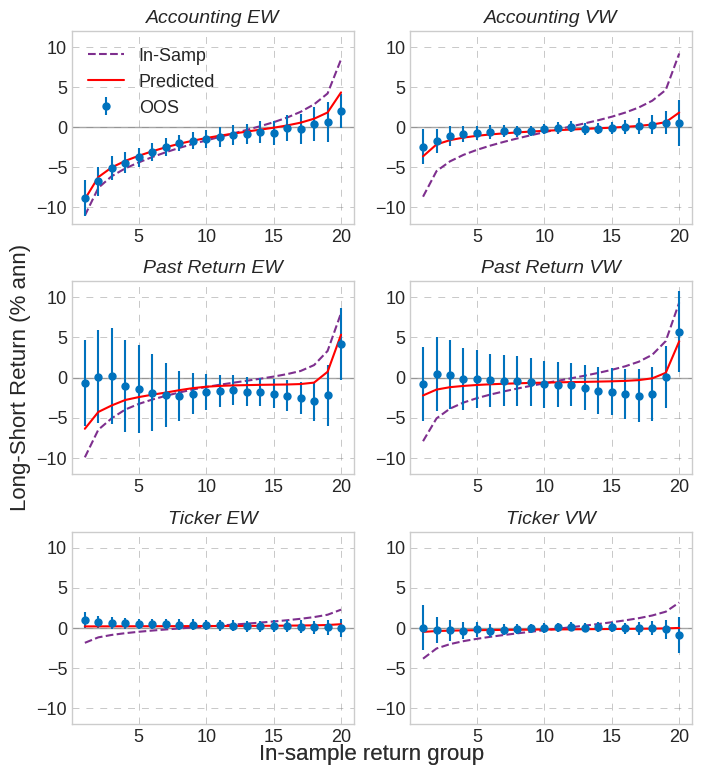

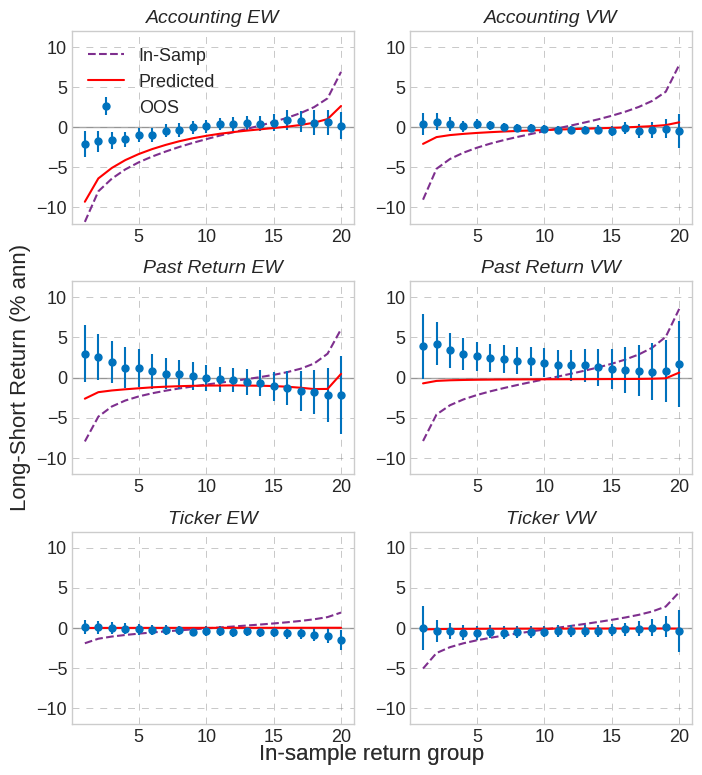

    Rank Sign  Pred. SR (ann)  OOS SR (ann) Signal Family  \
0      1    -            1.56          1.32       Acct EW   
1      2    -            1.51          0.84       Acct EW   
2      3    -            1.43          0.92       Acct EW   
3      4    -            1.37          1.60       Acct EW   
4      5    -            1.37          1.64       Acct EW   
5      6    +            1.36          0.54   Past Ret EW   
6      7    -            1.35          0.68       Acct EW   
7      8    -            1.35          0.69       Acct EW   
8      9    -            1.34          1.00       Acct EW   
9     10    +            1.33          0.47   Past Ret EW   
10    11    +            1.33          0.62   Past Ret EW   
11    12    -            1.33          0.62       Acct EW   
12    13    -            1.30          0.43       Acct EW   
13    14    +            1.30          0.44   Past Ret EW   
14    15    +            1.29          0.68   Past Ret EW   
15    16    -           

In [ ]:


#%% Plot IS, OOS and Prediced returns


ngroup = 20
year_set = [(1983, 2004),
            (2004, 2020),
            # (2020, 2022)
            ]

for year_min, year_max in year_set:
    temp = df_est_oos.query('@year_min<=oos_begin_year<=@year_max').copy()
    # yr_min, yr_max =  temp['oos_begin_year'].min(), temp['oos_begin_year'].max()

    cols = ['ret_is', 'ret_oos', 'pred_ret']
    temp[cols] = temp[cols] * ret_freq_adj

    temp['bin'] = temp.groupby(['signal_family', 'date'])['ret_is'].transform(
        lambda x: pd.qcut(x, ngroup, labels=np.arange(1, ngroup+1)))

    # summarize by family-oos_year-bin
    temp = temp.groupby(['signal_family', 'date', 'bin'], observed=True).agg(
        {'ret_is': 'mean',
        'ret_oos': 'mean',
        'pred_ret': 'mean'}
        )

    # get family-bin average and SD
    df = temp.groupby(['signal_family', 'bin'], observed=True).agg(
        {'ret_is': 'mean',
        'ret_oos': 'mean',
        'pred_ret': 'mean'}
        )

    df_se = temp.groupby(['signal_family', 'bin'], observed=True).agg(
        {'ret_oos': ['std', 'count']})
    df_se.columns = [c[1] for c in df_se.columns]
    df_se = (df_se['std']/np.sqrt(df_se['count']*oos_freq_adj)
             ).to_frame('se_ret_oos')
    df = df.merge(df_se, how='left', on=['signal_family', 'bin'])


    fig = plt.figure(figsize=(8,9))
    for i, family in enumerate(families_use):

        df1 = df.loc[family]
        ax = fig.add_subplot(3,2,i+1)

        ax.axhline(y=0, color='grey', alpha=0.7, linewidth=1)
        ax.plot(df1.index, df1['ret_is'], color=COLORS[3], linestyle='--', #alpha=0.7,
                label='In-Samp')
        ax.errorbar(df1.index, df1['ret_oos'], yerr=df1['se_ret_oos']*1.96,
                    fmt='o', markersize=5, color=COLORS[0], label='OOS')
        ax.plot(df1.index, df1['pred_ret'], color='red',
                label='Predicted')
        ax.set_ylim(-12, 12)
        plt.title(f'{FAMILY_LONG_NAME[family]}', fontsize=14, fontstyle='italic')
        plt.grid(color='grey', linestyle=(0, (10, 10)), linewidth=0.5, alpha=0.6)



        if i == 0:
            plt.legend(loc='upper left')
        if i == 2:
            ax.set_ylabel('Long-Short Return (% ann)', fontsize=16)
        fig.text(0.5, 0.07, 'In-sample return group', ha='center', fontsize=16,
                 color='k', alpha=0.25)


    plt.subplots_adjust(hspace=0.3)
    # plt.suptitle(f'Sample: {year_min}-{year_max}', y=0.95)
    fig.savefig(path_figs + f'pred-vs-oos-withIS-{year_min}-{year_max}.pdf', format='pdf',
                bbox_inches="tight")
    plt.show()


#%% Get best strategies based on predicted return, then compute OOS return


cols = ['signal_family','signalid','date', 'pred_ret',  'ret_oos', 'thetahat',
        'tstat_is', 'nobs','oos_begin_year']

qry = 'signal_family in @families_use & oos_begin_year<=@YEAR_MAX'
df_signed = df_est_oos.query(qry)[cols].copy()


####################
# sign the signals and return based on in-sample t-stat -- Naive Mining
####################
df_signed['sign_tstat'] = np.sign(df_signed['tstat_is'])
df_signed['tstat_is'] = df_signed['sign_tstat']*df_signed['tstat_is']
df_signed['ret_oos_tstat'] = df_signed['sign_tstat']*df_signed['ret_oos']
#  rank based on absolute t-stat
df_signed['rank_pct_tstat'] = df_signed.groupby('date')['tstat_is'].transform(
        lambda x: x.rank(pct=True)) * 100


####################
# sign the signals and return based on EB prediction -- EB Mining
####################
df_signed['sign'] = np.sign(df_signed['pred_ret'])
df_signed['pred_ret'] = df_signed['sign']*df_signed['pred_ret']
df_signed['ret_oos'] = df_signed['sign']*df_signed['ret_oos']
df_signed['thetahat'] = df_signed['sign']*df_signed['thetahat']
# find Sharpe ratio and rank based on it
df_signed['SRahat'] = (df_signed['thetahat']/np.sqrt(df_signed['nobs'])
                       )*np.sqrt(ret_freq_adj)
df_signed['rank_pct'] = df_signed.groupby('date')['SRahat'].transform(
        lambda x: x.rank(pct=True)) * 100


# get average return for stocks in top n%
extreme_ranks = [1, 5, 10]
df_best_ret = []
for sort_var, sfx in [('SRahat', ''), ('tstat_is', '_tstat')]:
    for rank in extreme_ranks:
        df = df_signed.loc[df_signed[f'rank_pct{sfx}']>=100-rank,
                           ['date', f'ret_oos{sfx}']].copy()
        df['ret_oos'] = df[f'ret_oos{sfx}']
        df = df.groupby('date').agg(ret_oos=('ret_oos', np.mean),
                                    nstrat=('ret_oos', 'count')).reset_index()
        df['pctmin'] = rank
        df['sort_var'] = sort_var
        df_best_ret.append(df)

df_best_ret = pd.concat(df_best_ret)



#%% OLD VERSION --- summarize best strategy together with published strategies

# #### prepare data for summarizing best performing strategies

# samp_split = 2004
# samp_start = df_best_ret['date'].min().year
# samp_end = df_best_ret['date'].max().year

# # for comparison, read in CZ returns
# pubret0 = pd.read_csv(path_input / 'PredictorLSretWide.csv')
# pubdoc = pd.read_excel(path_input / 'PredictorSummary.xlsx')
# pubdoc = pubdoc[['signalname', 'Year', 'SampleEndYear']].rename(
#     columns={'Year':'pubyear', 'SampleEndYear':'sampend'})

# # process CZ returns
# pubret = pd.melt(pubret0, id_vars='date', var_name='signalname', value_name='ret')
# pubret = pubret.query('ret.notnull()')
# pubret['date'] = pd.to_datetime(pubret['date'])
# pubret['year'] = pubret['date'].dt.year
# pubret = pubret.query('@samp_start <= year <= @samp_end')
# pubret = pubret.merge(pubdoc, how='left', on='signalname')

# pubcomb = []
# for nm, max_yr in [('Pub Anytime', samp_end), ('Pub Pre-2004', samp_split)]:
#     df1 = pubret.query('pubyear <= @max_yr')
#     # df1 = df1.groupby(['year', 'signalname'])[['ret']].mean()
#     df1 = df1.groupby('date').agg({'ret': ['mean', 'count']})
#     df1.columns = [f'{c[0]}_{c[1]}' for c in df1.columns]
#     df1 = df1.rename(columns={'ret_mean': 'ret', 'ret_count': 'nstrat'})
#     df1['name'] = nm
#     pubcomb.append(df1.reset_index())
# pubcomb = pd.concat(pubcomb)



# # merge CZ with best performing strategies
# # best_sumr = df_best_ret.drop(columns=['index'])
# sorting_types = [('SRahat', 'EB Mining'), ('tstat_is', 'Naive Mining')]
# for typ, lab in sorting_types:
#     print('\n\n', lab)
#     best_sumr = df_best_ret.query(
#         'sort_var == @typ').drop(columns=['sort_var']).copy()

#     best_sumr['pctmin'] = best_sumr['pctmin'].replace(
#         {1: f'{lab} Top 1\%', 5: f'{lab} Top 5\%', 10: f'{lab} Top 10\%',})
#     best_sumr = best_sumr.rename(columns={'pctmin': 'name', 'ret_oos':'ret'})


#     best_sumr = pd.concat([best_sumr, pubcomb])
#     best_sumr['year'] = best_sumr['date'].dt.year


#     # prepare table with best strategies summary
#     tabdat = []
#     sample_ls = [(1983, 2020), (1983, 2004), (2005, 2020)]
#     for min_yr, max_yr in sample_ls:
#         df = best_sumr.query("@min_yr<=year<=@max_yr")
#         df = df.groupby(["name"]).agg({
#             'ret': ['mean', 'std', 'count'],
#             'nstrat': 'mean'}
#             )
#         df.columns = [f'{c0}_{c1}' for c0, c1 in df.columns]
#         df['sr'] = df.eval('ret_mean/ret_std')
#         df['tstat'] = df.eval('ret_mean/ret_std*sqrt(ret_count)')
#         df = df.drop(columns=['ret_std', 'ret_count'])
#         df = df[['nstrat_mean', 'ret_mean', 'tstat', 'sr']]
#         df = df.loc[[f'{lab} Top 1\%',
#                      f'{lab} Top 5\%', f'{lab} Top 10\%',
#                      'Pub Anytime', 'Pub Pre-2004']]
#         line = pd.DataFrame(index=[f'{min_yr}-{max_yr}'], columns=df.columns)
#         df = pd.concat([line, df])
#         df.loc[''] = np.nan
#         tabdat.append(df)
#     tabdat = pd.concat(tabdat).iloc[:-1]

#     # annualize mean return
#     tabdat['ret_mean'] = tabdat['ret_mean'] * ret_freq_adj
#     # annualize sharpe ratio
#     tabdat['sr'] = tabdat['sr'] * np.sqrt(ret_freq_adj)

#     # some clean up
#     cols = ['ret_mean', 'tstat', 'sr']
#     tabdat[cols] = tabdat[cols].applymap(lambda x: f'{x:.2f}')
#     tabdat['nstrat_mean'] = tabdat['nstrat_mean'].apply(lambda x: f'{x:.0f}')
#     tabdat = tabdat.replace({'nan': ''})
#     print(tabdat)


#     tabdat = tabdat.rename(
#         columns={'nstrat_mean': '\makecell{Num Strats \\\\ Combined}',
#                   'ret_mean': '\makecell{Mean Return \\\\ (\% ann)}',
#                   'tstat': '$t$-stat', 'sr': '\makecell{Sharpe Ratio \\\\ (ann)}'})

#     # covert table to latex
#     col_format = 'l' + 'c' * tabdat.shape[1]
#     latex_table = tabdat.style.to_latex(column_format = col_format, hrules=True)
#     print(latex_table)

#     # clean latex table for saving and export it
#     part = r'\\\\\nPub Anytime'
#     repl = r'\\\\\n\\hline\nPub Anytime'
#     latex_tableF = re.sub(part, repl, latex_table)
#     part = r'\\\\\n &  &  &  &'
#     repl = r'\\\\\n\\hline\n &  &  &  &'
#     latex_tableF = re.sub(part, repl, latex_tableF)
#     part = r'(\n\d{4}\-\d{4} &  &  &  &  \\\\\n)'
#     repl =  r'\1\\hline\n'
#     latex_tableF = re.sub(part, repl, latex_tableF)
#     print(latex_tableF)

#     # save
#     sfx = '_'.join(lab.split(' '))
#     with open(path_tables / f'beststrats_{sfx}.tex', 'w') as fh:
#         fh.write(latex_tableF)


%% summarize best strategy together with published strategies

### prepare data for summarizing best performing strategies
samp_split = 2004
samp_start = df_best_ret['date'].min().year
samp_end = df_best_ret['date'].max().year

# for comparison, read in CZ returns
pubret0 = pd.read_csv('/content/PredictorLSretWide.csv')
pubdoc = pd.read_excel('/content/PredictorSummary.xlsx')
pubdoc = pubdoc[['signalname', 'Year', 'SampleEndYear']].rename(
    columns={'Year':'pubyear', 'SampleEndYear':'sampend'})

# process CZ returns
pubret = pd.melt(pubret0, id_vars='date', var_name='signalname', value_name='ret')
pubret = pubret.query('ret.notnull()')
pubret['date'] = pd.to_datetime(pubret['date'])
pubret['year'] = pubret['date'].dt.year
pubret = pubret.query('@samp_start <= year <= @samp_end')
pubret = pubret.merge(pubdoc, how='left', on='signalname')

pubcomb = []
for nm, max_yr in [('Pub Anytime', samp_end), ('Pub Pre-2004', samp_split)]:
    df1 = pubret.query('pubyear <= @max_yr')
    # df1 = df1.groupby(['year', 'signalname'])[['ret']].mean()
    df1 = df1.groupby('date').agg({'ret': ['mean', 'count']})
    df1.columns = [f'{c[0]}_{c[1]}' for c in df1.columns]
    df1 = df1.rename(columns={'ret_mean': 'ret', 'ret_count': 'nstrat'})
    df1['name'] = nm
    pubcomb.append(df1.reset_index())
pubcomb = pd.concat(pubcomb)
pubcomb['sort_var'] = 'published'


#nelly commented
# merge CZ with best performing strategies
# best_sumr = df_best_ret.drop(columns=['index'])
sorting_types = [('SRahat', 'EB Mining'), ('tstat_is', 'Naive Mining')]
best_sumr = df_best_ret.copy()
for typ, lab in sorting_types:
    mask = best_sumr['sort_var'] == typ
    best_sumr.loc[mask, 'pctmin'] = best_sumr.loc[mask, 'pctmin'].replace(
        {1: f'{lab} Top 1\%', 5: f'{lab} Top 5\%', 10: f'{lab} Top 10\%',})

best_sumr = best_sumr.rename(columns={'pctmin': 'name', 'ret_oos':'ret'})
best_sumr = pd.concat([best_sumr, pubcomb])
best_sumr['year'] = best_sumr['date'].dt.year


prepare table with best strategies summary
row_order = {
    'SRahat': ['EB Mining Top 1\%', 'EB Mining Top 5\%', 'EB Mining Top 10\%'],
    'tstat_is': ['Naive Mining Top 1\%', 'Naive Mining Top 5\%', 'Naive Mining Top 10\%'],
    'published': ['Pub Anytime', 'Pub Pre-2004']}
min_yr, max_yr = (1983, 2020)
sort_var_ls = ['SRahat', 'tstat_is', 'published']
alphabets = string.ascii_uppercase
tabdat = []
for i, sort_var in enumerate(sort_var_ls):
    df = best_sumr.query("sort_var==@sort_var")
    df = df.groupby(["name"]).agg({
        'ret': ['mean', 'std', 'count'],
        'nstrat': 'mean'}
        )
    df.columns = [f'{c0}_{c1}' for c0, c1 in df.columns]
    df['sr'] = df.eval('ret_mean/ret_std')
    df['tstat'] = df.eval('ret_mean/ret_std*sqrt(ret_count)')
    df = df.drop(columns=['ret_std', 'ret_count'])
    df = df[['nstrat_mean', 'ret_mean', 'tstat', 'sr']]
    df = df.loc[row_order[sort_var]]
    line = pd.DataFrame(index=[f'Panel {alphabets[i]}'], columns=df.columns)
    df = pd.concat([line, df])
    df.loc[''] = np.nan
    tabdat.append(df)
tabdat = pd.concat(tabdat).iloc[:-1]

# annualize mean return
tabdat['ret_mean'] = tabdat['ret_mean'] * ret_freq_adj
# annualize sharpe ratio
tabdat['sr'] = tabdat['sr'] * np.sqrt(ret_freq_adj)

# some clean up
cols = ['ret_mean', 'tstat', 'sr']
tabdat[cols] = tabdat[cols].applymap(lambda x: f'{x:.2f}')
tabdat['nstrat_mean'] = tabdat['nstrat_mean'].apply(lambda x: f'{x:.0f}')
tabdat = tabdat.replace({'nan': ''})
print(tabdat)


tabdat = tabdat.rename(
    columns={'nstrat_mean': '\makecell{Num Strats \\\\ Combined}',
              'ret_mean': '\makecell{Mean Return \\\\ (\% ann)}',
              'tstat': '$t$-stat', 'sr': '\makecell{Sharpe Ratio \\\\ (ann)}'})

# covert table to latex
col_format = 'l' + 'c' * tabdat.shape[1]
latex_table = tabdat.style.to_latex(column_format = col_format, hrules=True)
# print(latex_table)

# clean latex table for saving and export it
part = r'\\\\\n &  &  &  &'
repl = r'\\\\\n\\hline\n &  &  &  &'
latex_tableF = re.sub(part, repl, latex_table)
part = r'(\nPanel [A-Z] &  &  &  &  \\\\\n)'
repl =  r'\1\\hline\n'
latex_tableF = re.sub(part, repl, latex_tableF)
print('\n\n')
print(latex_tableF)

# save
with open(path_tables + 'beststrats.tex', 'w') as fh:
    fh.write(latex_tableF)



#%% plot cumulative performance of top n% strategies and published strategies


# get top DM strategies to plot
extreme_ranks_plot = [1, 5]
df = df_best_ret.query('pctmin in @extreme_ranks_plot').copy()
mask = df['sort_var'] == 'SRahat'
df.loc[mask, 'pctmin'] = df.loc[mask, 'pctmin'].replace(
    {1: 'EB mining top 1%', 5: 'EB mining top 5%', 10: 'EB mining top 10%',})
mask = df['sort_var'] == 'tstat_is'
df.loc[mask, 'pctmin'] = df.loc[mask, 'pctmin'].replace(
    {1: 'Naive mining top 1%', 5: 'Naive mining top 5%', 10: 'Naive mining top 10%',})

df = df.pivot(columns=['sort_var', 'pctmin'], index='date', values='ret_oos'
                       ).sort_index()

# merge with published strategies
temp = pubcomb.set_index(['name', 'date'])['ret'].unstack(0)
temp = temp.rename(columns={'Pub Anytime': 'Published anytime',
                    'Pub Pre-2004': 'Published pre-2004'})
temp.index = temp.index - pd.offsets.MonthBegin()
temp.columns = pd.MultiIndex.from_product([['published'], temp.columns])
df = df.join(temp)
# remove percent before cumulation of returns
df = (1 + df/100).cumprod()


# plot figure
color_dic = {'SRahat': (COLORS[0], 3),
             'tstat_is': (COLORS[1], 1.3),
             'published': (COLORS[3], 1.3)}
# fig, ax = plt.subplots(figsize=(7,5))
fig, ax = plt.subplots(figsize=(8,7))
for typ, params in color_dic.items():
    clr, lwidth = params
    temp = np.log(df[typ])
    temp.plot(ax=ax, color=[clr, clr], style=['-', '--'], linewidth=lwidth)

# plt.ylim(0, 10)
plt.grid(color='grey', linestyle=(0, (10, 10)), linewidth=0.5, alpha=0.6)
ax.set_ylabel('Log of value of $1 Invested in 1983')
ax.set_xlabel('')
plt.legend(loc='upper left', alignment='left')
fig.savefig(path_figs + 'beststrats-cret.pdf', format='pdf', bbox_inches="tight")
plt.show()


#%% get top 20 DM strategies in a specific year

fam_labels = {'acct_ew': 'Acct EW',
 'acct_vw': 'Acct VW',
 'past_ret_ew': 'Past Ret EW',
 'past_ret_vw': 'Past Ret VW',
 'ticker_ew': 'Ticker EW',
 'ticker_vw': 'Ticker VW',
#  'ravenpack_ew': 'News Sent EW',
#  'ravenpack_vw': 'News Sent VW'
 }



cols = ['signal_family','signalid', 'oos_begin_year', 'SRahat', 'sign']
df = df_signed[cols].drop_duplicates()
df['rank_pct'] = df.groupby('oos_begin_year')['SRahat'].transform(
        lambda x: x.rank(pct=True)) * 100

# get how many times each fiamily is in top 1 percent
top_1 = df.query('rank_pct >= 99')
top_1 = top_1.groupby(['oos_begin_year', 'signal_family'])['rank_pct'].count().to_frame('n_fam')
top_1['shr_fam'] = top_1['n_fam']/top_1['n_fam'].sum()
top_1 = top_1.groupby('signal_family')['shr_fam'].sum()
top_1 = top_1.rename(fam_labels)



# read signal definitions and merge with top
ret_sig_names = pd.read_csv('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/StrategyReturns/PastReturnSignalNames.csv.gzip')
ret_sig_names['family_root'] = 'past_ret'
acc_sig_names = pd.read_csv('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/DataMinedStrategies/DataMinedSignalList.csv')
acc_sig_names['family_root'] = 'acct'

# construct the account signal names
def get_acc_names(row):
    sid, sig_nm, v1, v2, _ = row.values
    return sig_nm.replace('v1', v1).replace('v2', v2)
acc_sig_names['signalname'] = acc_sig_names.apply(get_acc_names, axis=1)

cols = ['family_root', 'signalid', 'signalname']
df_sig_names = pd.concat([ret_sig_names[cols], acc_sig_names[cols]])


# yr = 1993
top_n = 20
top_strat_dic = {}
for yr in [1993, 2003, 2010, 2013]:
    df_top_n = df.query('oos_begin_year == @yr')
    df_top_n = df_top_n.nlargest(top_n, ['rank_pct'], keep='first'
                     ).sort_values('rank_pct', ascending=False)
    df_top_n['Rank'] = np.arange(1, len(df_top_n)+1)
    df_top_n['family_root'] = df_top_n['signal_family'].str.replace(r'_(ew|vw)', '', regex=True)


    # get realized sharpe ratio for the top_n strategies over the next 10 years
    yr_beg, yr_end = yr + 1, yr + 10
    df_ftr_ret = df_signed.query('@yr_beg <= oos_begin_year <= @yr_end')
    df_ftr_ret = df_ftr_ret.groupby(['signal_family', 'signalid']).agg(
        ret_mean=('ret_oos', np.mean), ret_std=('ret_oos', np.std))
    df_ftr_ret['SR_ftr'] = df_ftr_ret.eval('ret_mean/ret_std') * np.sqrt(ret_freq_adj)

    df_top_n = df_top_n.merge(df_ftr_ret[['SR_ftr']], how='left',
                              on=['signal_family', 'signalid'])
    # merge names to top_n data
    df_top_n = df_top_n.merge(df_sig_names, how='left', on=['family_root', 'signalid'])


    # final clean up for saving
    cols = ['Rank', 'sign', 'SRahat', 'SR_ftr', 'signal_family', 'signalname']
    df_top_n = df_top_n[cols]
    df_top_n[['SRahat', 'SR_ftr']] = df_top_n[['SRahat', 'SR_ftr']].round(2)
    df_top_n['signal_family'] = df_top_n['signal_family'].replace(fam_labels)
    df_top_n['sign'] = np.where(df_top_n['sign']==1, '+', '-')
    df_top_n = df_top_n.rename(columns={
        'SRahat': 'Pred. SR (ann)', 'signal_family': 'Signal Family',
        'signalname': 'Signal Name', 'SR_ftr': 'OOS SR (ann)', 'sign': 'Sign'
        })

    top_strat_dic[f'top_n_{yr}'] = df_top_n
    print(df_top_n)



# print(top_1)

with pd.ExcelWriter(path_tables + 'top_strategies_list.xlsx', mode='w') as ExcelHandle:
    top_1.to_excel(ExcelHandle, sheet_name='top_1%')
    for nm, df_top_n in top_strat_dic.items():
        df_top_n.to_excel(ExcelHandle, sheet_name=nm, index=False)


<>:287: SyntaxWarning: invalid escape sequence '\%'
<>:287: SyntaxWarning: invalid escape sequence '\%'
<>:287: SyntaxWarning: invalid escape sequence '\%'
<>:296: SyntaxWarning: invalid escape sequence '\%'
<>:296: SyntaxWarning: invalid escape sequence '\%'
<>:296: SyntaxWarning: invalid escape sequence '\%'
<>:297: SyntaxWarning: invalid escape sequence '\%'
<>:297: SyntaxWarning: invalid escape sequence '\%'
<>:297: SyntaxWarning: invalid escape sequence '\%'
<>:335: SyntaxWarning: invalid escape sequence '\m'
<>:336: SyntaxWarning: invalid escape sequence '\m'
<>:337: SyntaxWarning: invalid escape sequence '\m'
<>:287: SyntaxWarning: invalid escape sequence '\%'
<>:287: SyntaxWarning: invalid escape sequence '\%'
<>:287: SyntaxWarning: invalid escape sequence '\%'
<>:296: SyntaxWarning: invalid escape sequence '\%'
<>:296: SyntaxWarning: invalid escape sequence '\%'
<>:296: SyntaxWarning: invalid escape sequence '\%'
<>:297: SyntaxWarning: invalid escape sequence '\%'
<>:297: Synt

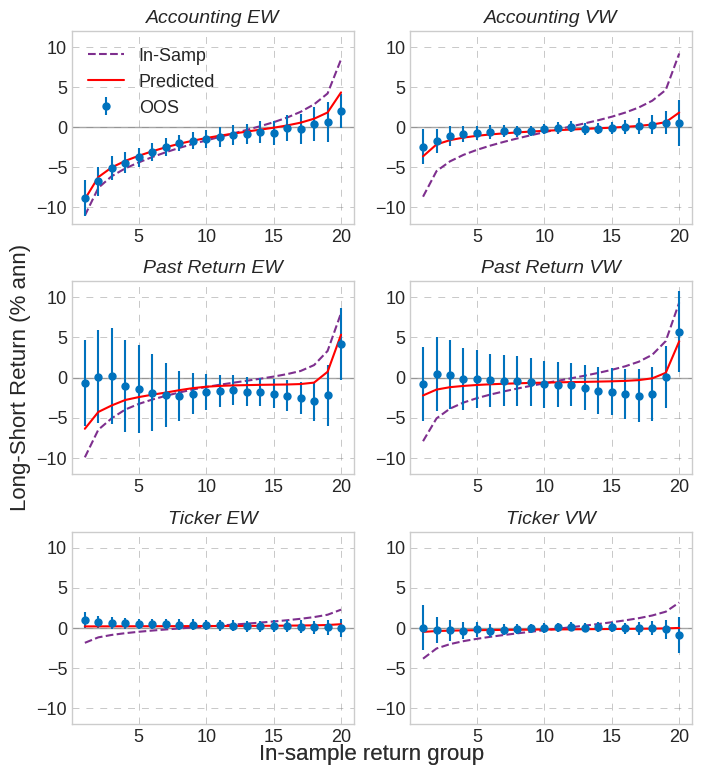

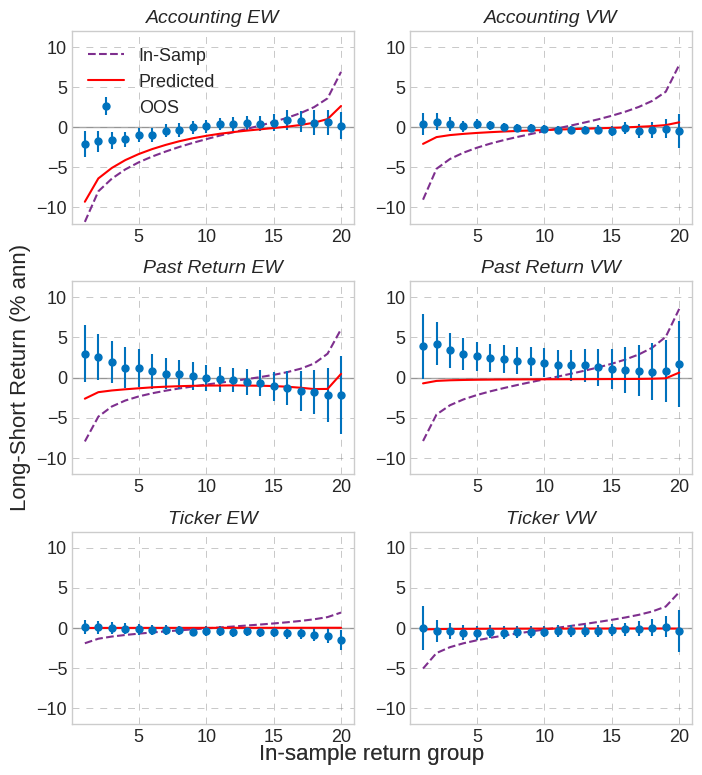

                      nstrat_mean ret_mean  tstat    sr
Panel A                                                
EB Mining Top 1\%            1278     5.70   9.01  1.46
EB Mining Top 5\%            6389     4.02   8.24  1.34
EB Mining Top 10\%          12777     2.76   7.14  1.16
                                                       
Panel B                                                
Naive Mining Top 1\%         1278     5.72   8.91  1.45
Naive Mining Top 5\%         6389     3.72   7.73  1.25
Naive Mining Top 10\%       12777     2.61   6.77  1.10
                                                       
Panel C                                                
Pub Anytime                   204     5.99  12.73  2.06
Pub Pre-2004                   82     5.27   9.76  1.58



\begin{tabular}{lcccc}
\toprule
 & \makecell{Num Strats \\ Combined} & \makecell{Mean Return \\ (\% ann)} & $t$-stat & \makecell{Sharpe Ratio \\ (ann)} \\
\midrule
Panel A &  &  &  &  \\
\hline
EB Mining Top 1\% &

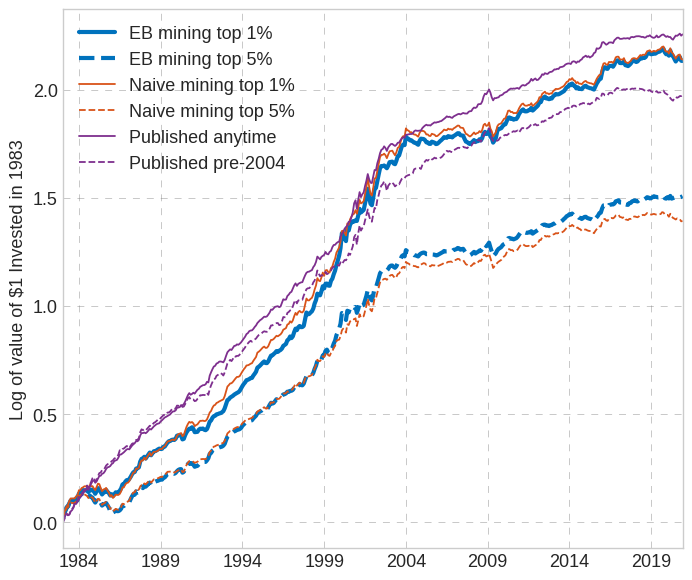

    Rank Sign  Pred. SR (ann)  OOS SR (ann) Signal Family  \
0      1    -            1.56          1.32       Acct EW   
1      2    -            1.51          0.84       Acct EW   
2      3    -            1.43          0.92       Acct EW   
3      4    -            1.37          1.60       Acct EW   
4      5    -            1.37          1.64       Acct EW   
5      6    +            1.36          0.54   Past Ret EW   
6      7    -            1.35          0.68       Acct EW   
7      8    -            1.35          0.69       Acct EW   
8      9    -            1.34          1.00       Acct EW   
9     10    +            1.33          0.47   Past Ret EW   
10    11    +            1.33          0.62   Past Ret EW   
11    12    -            1.33          0.62       Acct EW   
12    13    -            1.30          0.43       Acct EW   
13    14    +            1.30          0.44   Past Ret EW   
14    15    +            1.29          0.68   Past Ret EW   
15    16    -           

In [ ]:


#%% Plot IS, OOS and Prediced returns


ngroup = 20
year_set = [(1983, 2004),
            (2004, 2020),
            # (2020, 2022)
            ]

for year_min, year_max in year_set:
    temp = df_est_oos.query('@year_min<=oos_begin_year<=@year_max').copy()
    # yr_min, yr_max =  temp['oos_begin_year'].min(), temp['oos_begin_year'].max()

    cols = ['ret_is', 'ret_oos', 'pred_ret']
    temp[cols] = temp[cols] * ret_freq_adj

    temp['bin'] = temp.groupby(['signal_family', 'date'])['ret_is'].transform(
        lambda x: pd.qcut(x, ngroup, labels=np.arange(1, ngroup+1)))

    # summarize by family-oos_year-bin
    temp = temp.groupby(['signal_family', 'date', 'bin'], observed=True).agg(
        {'ret_is': 'mean',
        'ret_oos': 'mean',
        'pred_ret': 'mean'}
        )

    # get family-bin average and SD
    df = temp.groupby(['signal_family', 'bin'], observed=True).agg(
        {'ret_is': 'mean',
        'ret_oos': 'mean',
        'pred_ret': 'mean'}
        )

    df_se = temp.groupby(['signal_family', 'bin'], observed=True).agg(
        {'ret_oos': ['std', 'count']})
    df_se.columns = [c[1] for c in df_se.columns]
    df_se = (df_se['std']/np.sqrt(df_se['count']*oos_freq_adj)
             ).to_frame('se_ret_oos')
    df = df.merge(df_se, how='left', on=['signal_family', 'bin'])


    fig = plt.figure(figsize=(8,9))
    for i, family in enumerate(families_use):

        df1 = df.loc[family]
        ax = fig.add_subplot(3,2,i+1)

        ax.axhline(y=0, color='grey', alpha=0.7, linewidth=1)
        ax.plot(df1.index, df1['ret_is'], color=COLORS[3], linestyle='--', #alpha=0.7,
                label='In-Samp')
        ax.errorbar(df1.index, df1['ret_oos'], yerr=df1['se_ret_oos']*1.96,
                    fmt='o', markersize=5, color=COLORS[0], label='OOS')
        ax.plot(df1.index, df1['pred_ret'], color='red',
                label='Predicted')
        ax.set_ylim(-12, 12)
        plt.title(f'{FAMILY_LONG_NAME[family]}', fontsize=14, fontstyle='italic')
        plt.grid(color='grey', linestyle=(0, (10, 10)), linewidth=0.5, alpha=0.6)



        if i == 0:
            plt.legend(loc='upper left')
        if i == 2:
            ax.set_ylabel('Long-Short Return (% ann)', fontsize=16)
        fig.text(0.5, 0.07, 'In-sample return group', ha='center', fontsize=16,
                 color='k', alpha=0.25)


    plt.subplots_adjust(hspace=0.3)
    # plt.suptitle(f'Sample: {year_min}-{year_max}', y=0.95)
    fig.savefig(path_figs + f'pred-vs-oos-withIS-{year_min}-{year_max}.pdf', format='pdf',
                bbox_inches="tight")
    plt.show()


#%% Get best strategies based on predicted return, then compute OOS return


cols = ['signal_family','signalid','date', 'pred_ret',  'ret_oos', 'thetahat',
        'tstat_is', 'nobs','oos_begin_year']

qry = 'signal_family in @families_use & oos_begin_year<=@YEAR_MAX'
df_signed = df_est_oos.query(qry)[cols].copy()


####################
# sign the signals and return based on in-sample t-stat -- Naive Mining
####################
df_signed['sign_tstat'] = np.sign(df_signed['tstat_is'])
df_signed['tstat_is'] = df_signed['sign_tstat']*df_signed['tstat_is']
df_signed['ret_oos_tstat'] = df_signed['sign_tstat']*df_signed['ret_oos']
#  rank based on absolute t-stat
df_signed['rank_pct_tstat'] = df_signed.groupby('date')['tstat_is'].transform(
        lambda x: x.rank(pct=True)) * 100


####################
# sign the signals and return based on EB prediction -- EB Mining
####################
df_signed['sign'] = np.sign(df_signed['pred_ret'])
df_signed['pred_ret'] = df_signed['sign']*df_signed['pred_ret']
df_signed['ret_oos'] = df_signed['sign']*df_signed['ret_oos']
df_signed['thetahat'] = df_signed['sign']*df_signed['thetahat']
# find Sharpe ratio and rank based on it
df_signed['SRahat'] = (df_signed['thetahat']/np.sqrt(df_signed['nobs'])
                       )*np.sqrt(ret_freq_adj)
df_signed['rank_pct'] = df_signed.groupby('date')['SRahat'].transform(
        lambda x: x.rank(pct=True)) * 100


# get average return for stocks in top n%
extreme_ranks = [1, 5, 10]
df_best_ret = []
for sort_var, sfx in [('SRahat', ''), ('tstat_is', '_tstat')]:
    for rank in extreme_ranks:
        df = df_signed.loc[df_signed[f'rank_pct{sfx}']>=100-rank,
                           ['date', f'ret_oos{sfx}']].copy()
        df['ret_oos'] = df[f'ret_oos{sfx}']
        df = df.groupby('date').agg(ret_oos=('ret_oos', np.mean),
                                    nstrat=('ret_oos', 'count')).reset_index()
        df['pctmin'] = rank
        df['sort_var'] = sort_var
        df_best_ret.append(df)

df_best_ret = pd.concat(df_best_ret)



#%% OLD VERSION --- summarize best strategy together with published strategies

# #### prepare data for summarizing best performing strategies

# samp_split = 2004
# samp_start = df_best_ret['date'].min().year
# samp_end = df_best_ret['date'].max().year

# # for comparison, read in CZ returns
# pubret0 = pd.read_csv(path_input / 'PredictorLSretWide.csv')
# pubdoc = pd.read_excel(path_input / 'PredictorSummary.xlsx')
# pubdoc = pubdoc[['signalname', 'Year', 'SampleEndYear']].rename(
#     columns={'Year':'pubyear', 'SampleEndYear':'sampend'})

# # process CZ returns
# pubret = pd.melt(pubret0, id_vars='date', var_name='signalname', value_name='ret')
# pubret = pubret.query('ret.notnull()')
# pubret['date'] = pd.to_datetime(pubret['date'])
# pubret['year'] = pubret['date'].dt.year
# pubret = pubret.query('@samp_start <= year <= @samp_end')
# pubret = pubret.merge(pubdoc, how='left', on='signalname')

# pubcomb = []
# for nm, max_yr in [('Pub Anytime', samp_end), ('Pub Pre-2004', samp_split)]:
#     df1 = pubret.query('pubyear <= @max_yr')
#     # df1 = df1.groupby(['year', 'signalname'])[['ret']].mean()
#     df1 = df1.groupby('date').agg({'ret': ['mean', 'count']})
#     df1.columns = [f'{c[0]}_{c[1]}' for c in df1.columns]
#     df1 = df1.rename(columns={'ret_mean': 'ret', 'ret_count': 'nstrat'})
#     df1['name'] = nm
#     pubcomb.append(df1.reset_index())
# pubcomb = pd.concat(pubcomb)



# # merge CZ with best performing strategies
# # best_sumr = df_best_ret.drop(columns=['index'])
# sorting_types = [('SRahat', 'EB Mining'), ('tstat_is', 'Naive Mining')]
# for typ, lab in sorting_types:
#     print('\n\n', lab)
#     best_sumr = df_best_ret.query(
#         'sort_var == @typ').drop(columns=['sort_var']).copy()

#     best_sumr['pctmin'] = best_sumr['pctmin'].replace(
#         {1: f'{lab} Top 1\%', 5: f'{lab} Top 5\%', 10: f'{lab} Top 10\%',})
#     best_sumr = best_sumr.rename(columns={'pctmin': 'name', 'ret_oos':'ret'})


#     best_sumr = pd.concat([best_sumr, pubcomb])
#     best_sumr['year'] = best_sumr['date'].dt.year


#     # prepare table with best strategies summary
#     tabdat = []
#     sample_ls = [(1983, 2020), (1983, 2004), (2005, 2020)]
#     for min_yr, max_yr in sample_ls:
#         df = best_sumr.query("@min_yr<=year<=@max_yr")
#         df = df.groupby(["name"]).agg({
#             'ret': ['mean', 'std', 'count'],
#             'nstrat': 'mean'}
#             )
#         df.columns = [f'{c0}_{c1}' for c0, c1 in df.columns]
#         df['sr'] = df.eval('ret_mean/ret_std')
#         df['tstat'] = df.eval('ret_mean/ret_std*sqrt(ret_count)')
#         df = df.drop(columns=['ret_std', 'ret_count'])
#         df = df[['nstrat_mean', 'ret_mean', 'tstat', 'sr']]
#         df = df.loc[[f'{lab} Top 1\%',
#                      f'{lab} Top 5\%', f'{lab} Top 10\%',
#                      'Pub Anytime', 'Pub Pre-2004']]
#         line = pd.DataFrame(index=[f'{min_yr}-{max_yr}'], columns=df.columns)
#         df = pd.concat([line, df])
#         df.loc[''] = np.nan
#         tabdat.append(df)
#     tabdat = pd.concat(tabdat).iloc[:-1]

#     # annualize mean return
#     tabdat['ret_mean'] = tabdat['ret_mean'] * ret_freq_adj
#     # annualize sharpe ratio
#     tabdat['sr'] = tabdat['sr'] * np.sqrt(ret_freq_adj)

#     # some clean up
#     cols = ['ret_mean', 'tstat', 'sr']
#     tabdat[cols] = tabdat[cols].applymap(lambda x: f'{x:.2f}')
#     tabdat['nstrat_mean'] = tabdat['nstrat_mean'].apply(lambda x: f'{x:.0f}')
#     tabdat = tabdat.replace({'nan': ''})
#     print(tabdat)


#     tabdat = tabdat.rename(
#         columns={'nstrat_mean': '\makecell{Num Strats \\\\ Combined}',
#                   'ret_mean': '\makecell{Mean Return \\\\ (\% ann)}',
#                   'tstat': '$t$-stat', 'sr': '\makecell{Sharpe Ratio \\\\ (ann)}'})

#     # covert table to latex
#     col_format = 'l' + 'c' * tabdat.shape[1]
#     latex_table = tabdat.style.to_latex(column_format = col_format, hrules=True)
#     print(latex_table)

#     # clean latex table for saving and export it
#     part = r'\\\\\nPub Anytime'
#     repl = r'\\\\\n\\hline\nPub Anytime'
#     latex_tableF = re.sub(part, repl, latex_table)
#     part = r'\\\\\n &  &  &  &'
#     repl = r'\\\\\n\\hline\n &  &  &  &'
#     latex_tableF = re.sub(part, repl, latex_tableF)
#     part = r'(\n\d{4}\-\d{4} &  &  &  &  \\\\\n)'
#     repl =  r'\1\\hline\n'
#     latex_tableF = re.sub(part, repl, latex_tableF)
#     print(latex_tableF)

#     # save
#     sfx = '_'.join(lab.split(' '))
#     with open(path_tables / f'beststrats_{sfx}.tex', 'w') as fh:
#         fh.write(latex_tableF)


# %% summarize best strategy together with published strategies

### prepare data for summarizing best performing strategies
samp_split = 2004
samp_start = df_best_ret['date'].min().year
samp_end = df_best_ret['date'].max().year

# for comparison, read in CZ returns
pubret0 = pd.read_csv('/content/PredictorLSretWide.csv')
pubdoc = pd.read_excel('/content/PredictorSummary.xlsx')
pubdoc = pubdoc[['signalname', 'Year', 'SampleEndYear']].rename(
    columns={'Year':'pubyear', 'SampleEndYear':'sampend'})

# process CZ returns
pubret = pd.melt(pubret0, id_vars='date', var_name='signalname', value_name='ret')
pubret = pubret.query('ret.notnull()')
pubret['date'] = pd.to_datetime(pubret['date'])
pubret['year'] = pubret['date'].dt.year
pubret = pubret.query('@samp_start <= year <= @samp_end')
pubret = pubret.merge(pubdoc, how='left', on='signalname')

pubcomb = []
for nm, max_yr in [('Pub Anytime', samp_end), ('Pub Pre-2004', samp_split)]:
    df1 = pubret.query('pubyear <= @max_yr')
    # df1 = df1.groupby(['year', 'signalname'])[['ret']].mean()
    df1 = df1.groupby('date').agg({'ret': ['mean', 'count']})
    df1.columns = [f'{c[0]}_{c[1]}' for c in df1.columns]
    df1 = df1.rename(columns={'ret_mean': 'ret', 'ret_count': 'nstrat'})
    df1['name'] = nm
    pubcomb.append(df1.reset_index())
pubcomb = pd.concat(pubcomb)
pubcomb['sort_var'] = 'published'


#nelly commented
# merge CZ with best performing strategies
# best_sumr = df_best_ret.drop(columns=['index'])
sorting_types = [('SRahat', 'EB Mining'), ('tstat_is', 'Naive Mining')]
best_sumr = df_best_ret.copy()
for typ, lab in sorting_types:
    mask = best_sumr['sort_var'] == typ
    best_sumr.loc[mask, 'pctmin'] = best_sumr.loc[mask, 'pctmin'].replace(
        {1: f'{lab} Top 1\%', 5: f'{lab} Top 5\%', 10: f'{lab} Top 10\%',})

best_sumr = best_sumr.rename(columns={'pctmin': 'name', 'ret_oos':'ret'})
best_sumr = pd.concat([best_sumr, pubcomb])
best_sumr['year'] = best_sumr['date'].dt.year


# prepare table with best strategies summary
row_order = {
    'SRahat': ['EB Mining Top 1\%', 'EB Mining Top 5\%', 'EB Mining Top 10\%'],
    'tstat_is': ['Naive Mining Top 1\%', 'Naive Mining Top 5\%', 'Naive Mining Top 10\%'],
    'published': ['Pub Anytime', 'Pub Pre-2004']}
min_yr, max_yr = (1983, 2020)
sort_var_ls = ['SRahat', 'tstat_is', 'published']
alphabets = string.ascii_uppercase
tabdat = []
for i, sort_var in enumerate(sort_var_ls):
    df = best_sumr.query("sort_var==@sort_var")
    df = df.groupby(["name"]).agg({
        'ret': ['mean', 'std', 'count'],
        'nstrat': 'mean'}
        )
    df.columns = [f'{c0}_{c1}' for c0, c1 in df.columns]
    df['sr'] = df.eval('ret_mean/ret_std')
    df['tstat'] = df.eval('ret_mean/ret_std*sqrt(ret_count)')
    df = df.drop(columns=['ret_std', 'ret_count'])
    df = df[['nstrat_mean', 'ret_mean', 'tstat', 'sr']]
    df = df.loc[row_order[sort_var]]
    line = pd.DataFrame(index=[f'Panel {alphabets[i]}'], columns=df.columns)
    df = pd.concat([line, df])
    df.loc[''] = np.nan
    tabdat.append(df)
tabdat = pd.concat(tabdat).iloc[:-1]

# annualize mean return
tabdat['ret_mean'] = tabdat['ret_mean'] * ret_freq_adj
# annualize sharpe ratio
tabdat['sr'] = tabdat['sr'] * np.sqrt(ret_freq_adj)

# some clean up
cols = ['ret_mean', 'tstat', 'sr']
tabdat[cols] = tabdat[cols].applymap(lambda x: f'{x:.2f}')
tabdat['nstrat_mean'] = tabdat['nstrat_mean'].apply(lambda x: f'{x:.0f}')
tabdat = tabdat.replace({'nan': ''})
print(tabdat)


tabdat = tabdat.rename(
    columns={'nstrat_mean': '\makecell{Num Strats \\\\ Combined}',
              'ret_mean': '\makecell{Mean Return \\\\ (\% ann)}',
              'tstat': '$t$-stat', 'sr': '\makecell{Sharpe Ratio \\\\ (ann)}'})

# covert table to latex
col_format = 'l' + 'c' * tabdat.shape[1]
latex_table = tabdat.style.to_latex(column_format = col_format, hrules=True)
# print(latex_table)

# clean latex table for saving and export it
part = r'\\\\\n &  &  &  &'
repl = r'\\\\\n\\hline\n &  &  &  &'
latex_tableF = re.sub(part, repl, latex_table)
part = r'(\nPanel [A-Z] &  &  &  &  \\\\\n)'
repl =  r'\1\\hline\n'
latex_tableF = re.sub(part, repl, latex_tableF)
print('\n\n')
print(latex_tableF)

# save
with open(path_tables + 'beststrats.tex', 'w') as fh:
    fh.write(latex_tableF)



#%% plot cumulative performance of top n% strategies and published strategies


# get top DM strategies to plot
extreme_ranks_plot = [1, 5]
df = df_best_ret.query('pctmin in @extreme_ranks_plot').copy()
mask = df['sort_var'] == 'SRahat'
df.loc[mask, 'pctmin'] = df.loc[mask, 'pctmin'].replace(
    {1: 'EB mining top 1%', 5: 'EB mining top 5%', 10: 'EB mining top 10%',})
mask = df['sort_var'] == 'tstat_is'
df.loc[mask, 'pctmin'] = df.loc[mask, 'pctmin'].replace(
    {1: 'Naive mining top 1%', 5: 'Naive mining top 5%', 10: 'Naive mining top 10%',})

df = df.pivot(columns=['sort_var', 'pctmin'], index='date', values='ret_oos'
                       ).sort_index()

# merge with published strategies
temp = pubcomb.set_index(['name', 'date'])['ret'].unstack(0)
temp = temp.rename(columns={'Pub Anytime': 'Published anytime',
                    'Pub Pre-2004': 'Published pre-2004'})
temp.index = temp.index - pd.offsets.MonthBegin()
temp.columns = pd.MultiIndex.from_product([['published'], temp.columns])
df = df.join(temp)
# remove percent before cumulation of returns
df = (1 + df/100).cumprod()


# plot figure
color_dic = {'SRahat': (COLORS[0], 3),
             'tstat_is': (COLORS[1], 1.3),
             'published': (COLORS[3], 1.3)}
# fig, ax = plt.subplots(figsize=(7,5))
fig, ax = plt.subplots(figsize=(8,7))
for typ, params in color_dic.items():
    clr, lwidth = params
    temp = np.log(df[typ])
    temp.plot(ax=ax, color=[clr, clr], style=['-', '--'], linewidth=lwidth)

# plt.ylim(0, 10)
plt.grid(color='grey', linestyle=(0, (10, 10)), linewidth=0.5, alpha=0.6)
ax.set_ylabel('Log of value of $1 Invested in 1983')
ax.set_xlabel('')
plt.legend(loc='upper left', alignment='left')
fig.savefig(path_figs + 'beststrats-cret.pdf', format='pdf', bbox_inches="tight")
plt.show()


#%% get top 20 DM strategies in a specific year

fam_labels = {'acct_ew': 'Acct EW',
 'acct_vw': 'Acct VW',
 'past_ret_ew': 'Past Ret EW',
 'past_ret_vw': 'Past Ret VW',
 'ticker_ew': 'Ticker EW',
 'ticker_vw': 'Ticker VW',
#  'ravenpack_ew': 'News Sent EW',
#  'ravenpack_vw': 'News Sent VW'
 }



cols = ['signal_family','signalid', 'oos_begin_year', 'SRahat', 'sign']
df = df_signed[cols].drop_duplicates()
df['rank_pct'] = df.groupby('oos_begin_year')['SRahat'].transform(
        lambda x: x.rank(pct=True)) * 100

# get how many times each fiamily is in top 1 percent
top_1 = df.query('rank_pct >= 99')
top_1 = top_1.groupby(['oos_begin_year', 'signal_family'])['rank_pct'].count().to_frame('n_fam')
top_1['shr_fam'] = top_1['n_fam']/top_1['n_fam'].sum()
top_1 = top_1.groupby('signal_family')['shr_fam'].sum()
top_1 = top_1.rename(fam_labels)



# read signal definitions and merge with top
ret_sig_names = pd.read_csv('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/StrategyReturns/PastReturnSignalNames.csv.gzip')
ret_sig_names['family_root'] = 'past_ret'
acc_sig_names = pd.read_csv('/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data/DataMinedStrategies/DataMinedSignalList.csv')
acc_sig_names['family_root'] = 'acct'

# construct the account signal names
def get_acc_names(row):
    sid, sig_nm, v1, v2, _ = row.values
    return sig_nm.replace('v1', v1).replace('v2', v2)
acc_sig_names['signalname'] = acc_sig_names.apply(get_acc_names, axis=1)

cols = ['family_root', 'signalid', 'signalname']
df_sig_names = pd.concat([ret_sig_names[cols], acc_sig_names[cols]])


# yr = 1993
top_n = 20
top_strat_dic = {}
for yr in [1993, 2003, 2010, 2013]:
    df_top_n = df.query('oos_begin_year == @yr')
    df_top_n = df_top_n.nlargest(top_n, ['rank_pct'], keep='first'
                     ).sort_values('rank_pct', ascending=False)
    df_top_n['Rank'] = np.arange(1, len(df_top_n)+1)
    df_top_n['family_root'] = df_top_n['signal_family'].str.replace(r'_(ew|vw)', '', regex=True)


    # get realized sharpe ratio for the top_n strategies over the next 10 years
    yr_beg, yr_end = yr + 1, yr + 10
    df_ftr_ret = df_signed.query('@yr_beg <= oos_begin_year <= @yr_end')
    df_ftr_ret = df_ftr_ret.groupby(['signal_family', 'signalid']).agg(
        ret_mean=('ret_oos', np.mean), ret_std=('ret_oos', np.std))
    df_ftr_ret['SR_ftr'] = df_ftr_ret.eval('ret_mean/ret_std') * np.sqrt(ret_freq_adj)

    df_top_n = df_top_n.merge(df_ftr_ret[['SR_ftr']], how='left',
                              on=['signal_family', 'signalid'])
    # merge names to top_n data
    df_top_n = df_top_n.merge(df_sig_names, how='left', on=['family_root', 'signalid'])


    # final clean up for saving
    cols = ['Rank', 'sign', 'SRahat', 'SR_ftr', 'signal_family', 'signalname']
    df_top_n = df_top_n[cols]
    df_top_n[['SRahat', 'SR_ftr']] = df_top_n[['SRahat', 'SR_ftr']].round(2)
    df_top_n['signal_family'] = df_top_n['signal_family'].replace(fam_labels)
    df_top_n['sign'] = np.where(df_top_n['sign']==1, '+', '-')
    df_top_n = df_top_n.rename(columns={
        'SRahat': 'Pred. SR (ann)', 'signal_family': 'Signal Family',
        'signalname': 'Signal Name', 'SR_ftr': 'OOS SR (ann)', 'sign': 'Sign'
        })

    top_strat_dic[f'top_n_{yr}'] = df_top_n
    print(df_top_n)



# print(top_1)

with pd.ExcelWriter(path_tables + 'top_strategies_list.xlsx', mode='w') as ExcelHandle:
    top_1.to_excel(ExcelHandle, sheet_name='top_1%')
    for nm, df_top_n in top_strat_dic.items():
        df_top_n.to_excel(ExcelHandle, sheet_name=nm, index=False)


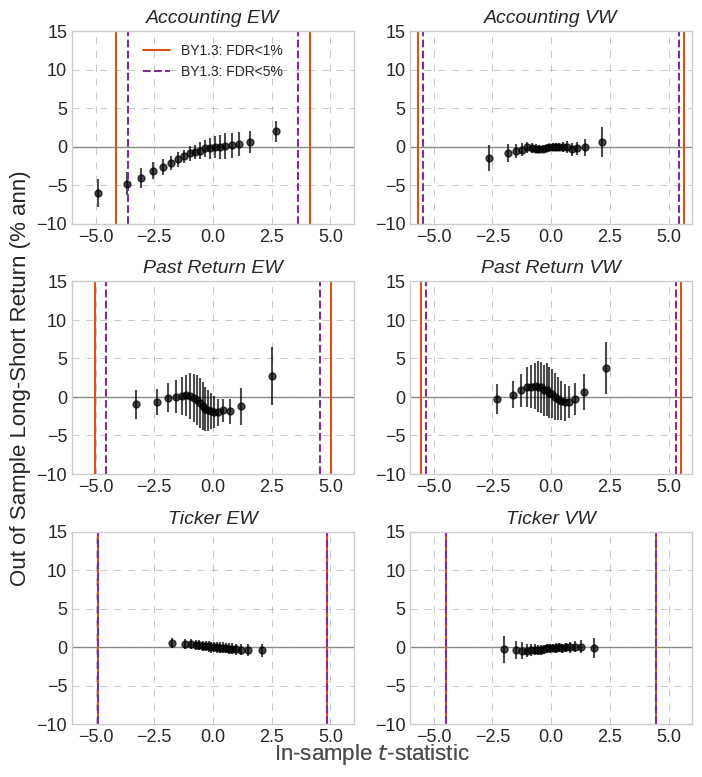

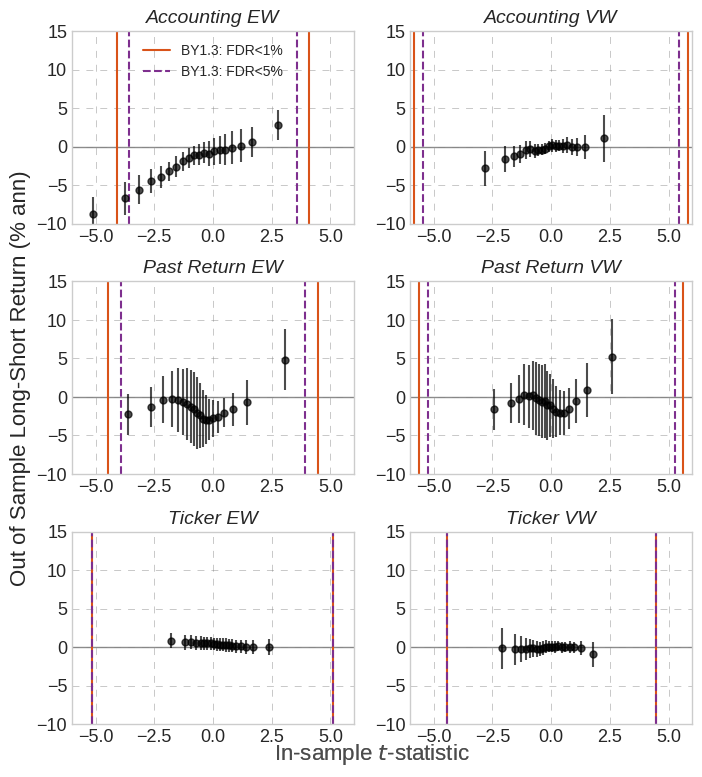

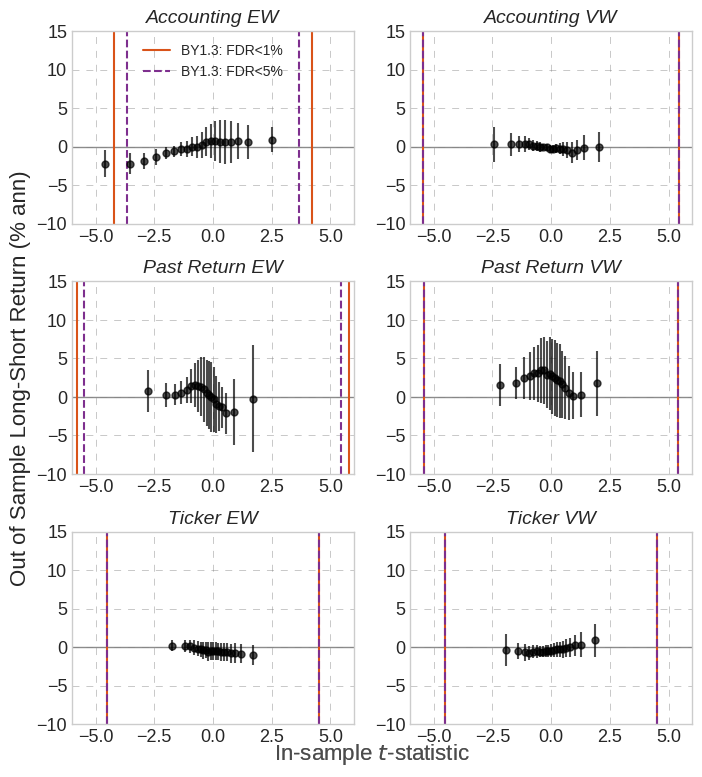

/tmp/ipykernel_637/1440772442.py:186: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df2 = df.groupby(['signal_family', 'oos_begin_year']).apply(


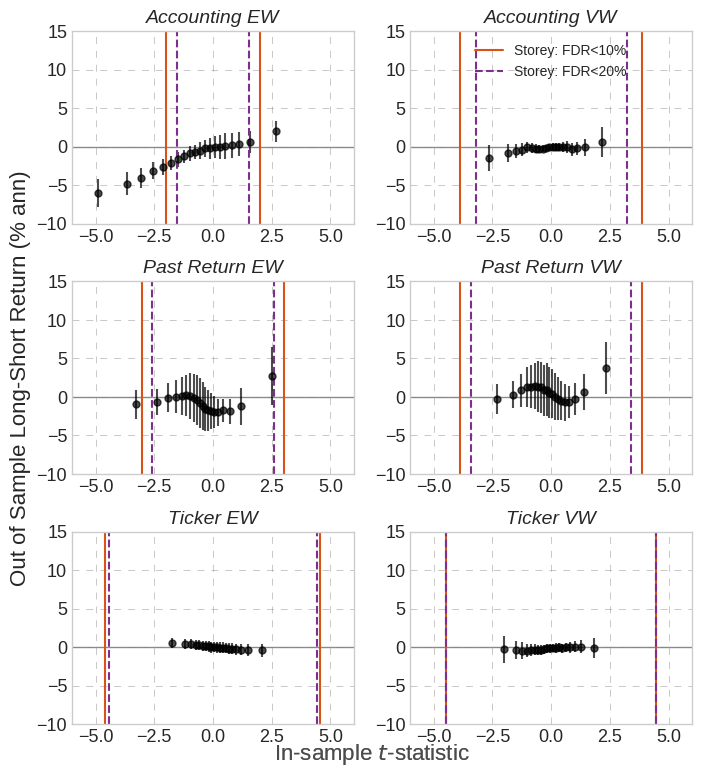

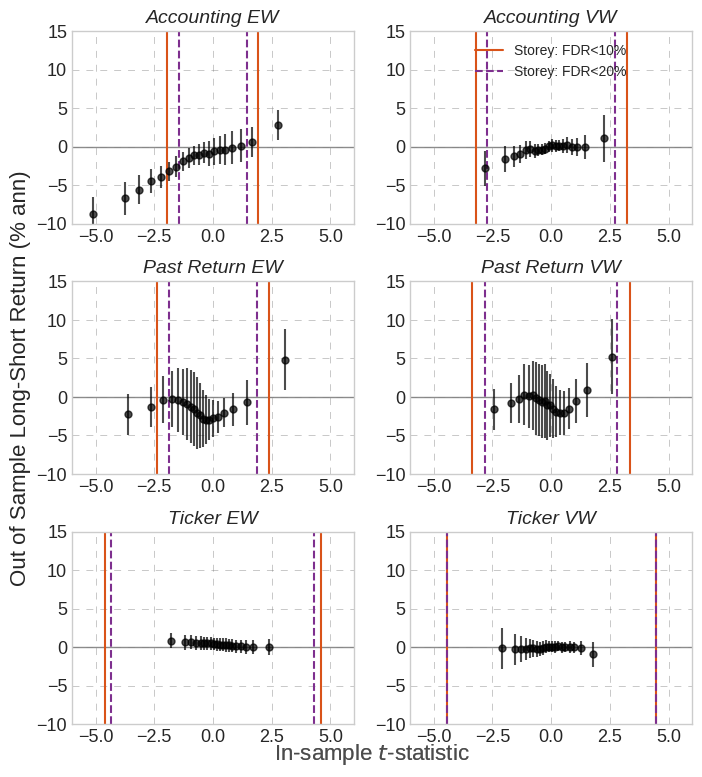

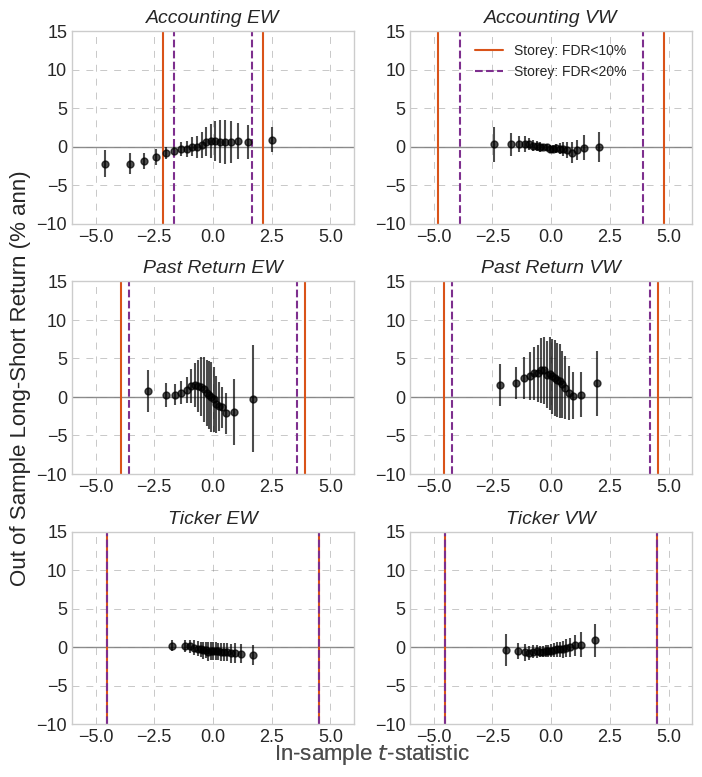

/tmp/ipykernel_637/1440772442.py:186: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df2 = df.groupby(['signal_family', 'oos_begin_year']).apply(


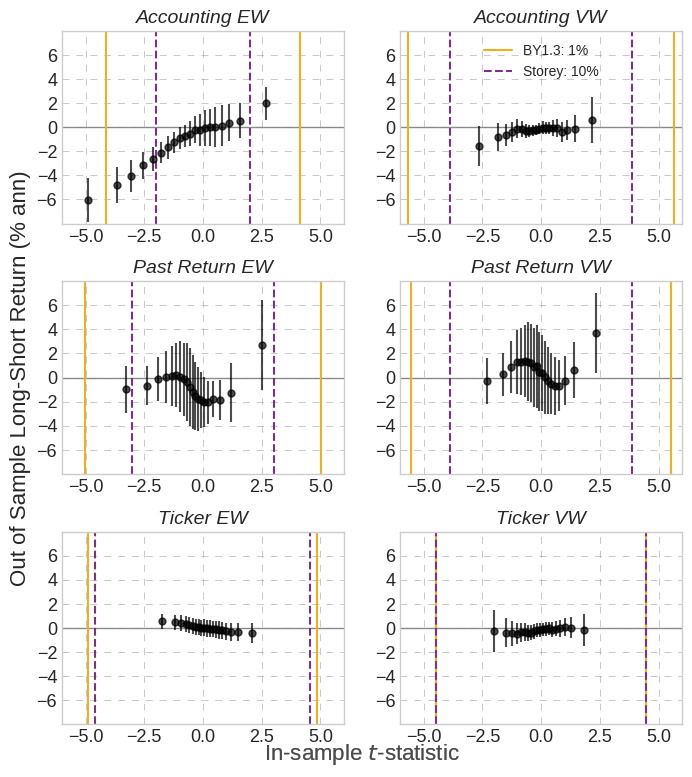

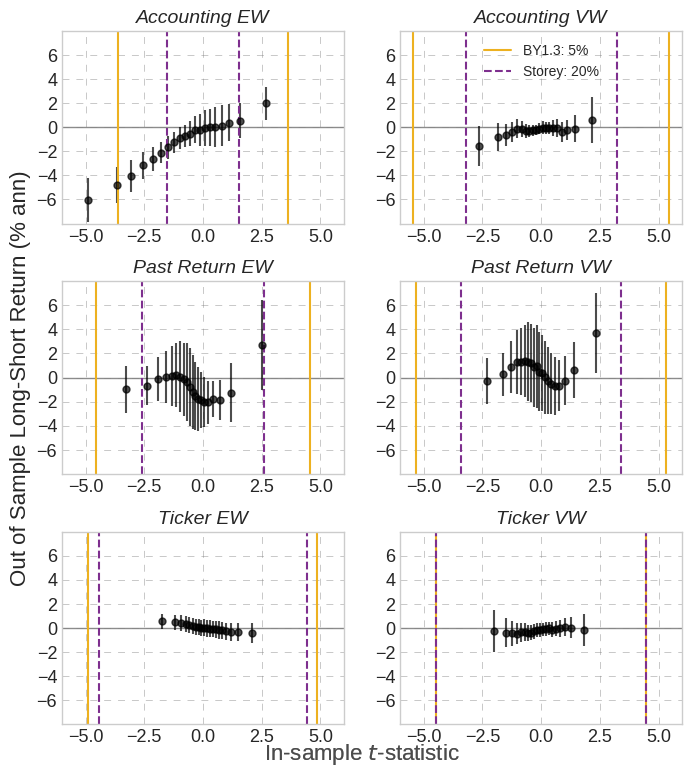

In [ ]:


#%% HLZ's preferred Benji-Yeki Theorem 1.3 control

# Get t-stat hurdles
rollfamFDR = get_BY_tstat_hurdles(df_est_oos)


# find oos returns by tstat bin
ngroup = 20
rollbin = df_est_oos.copy()

cols = ['ret_is', 'ret_oos']
rollbin[cols] = rollbin[cols] * ret_freq_adj

rollbin['group'] = rollbin.groupby(['signal_family', 'oos_begin_year'])[
    'tstat_is'].transform(lambda x: pd.qcut(x, ngroup, labels=np.arange(1,ngroup+1))
                          ).astype(int)
rollbin = rollbin.groupby(['signal_family', 'oos_begin_year', 'group']).agg(
    {'ret_oos': 'mean',
     'ret_is': 'mean',
     'tstat_is': 'mean',
     }).reset_index()



# prepare result and plot

sample_ls = [(1983, 2020), (1983, 2004), (2005, 2020)]
for min_yr, max_yr in sample_ls:
    sumfamFDR = rollfamFDR.query('@min_yr <= oos_begin_year <= @max_yr')
    sumfamFDR = sumfamFDR.groupby(['signal_family', 'crit_level'])['tabs_hurdle'].mean()
    sumfamFDR = sumfamFDR.unstack()
    sumfamFDR.columns = [f'crit_{v}' for v in sumfamFDR.columns]

    temp = rollbin.query('@min_yr <= oos_begin_year <= @max_yr')
    sumbin = temp.groupby(['signal_family', 'group'], observed=True).agg(
        {'ret_is': 'mean',
        'ret_oos': 'mean',
        'tstat_is': 'mean'}
        ).reset_index()

    df_se = temp.groupby(['signal_family', 'group'], observed=True).agg(
        {'ret_oos': ['std', 'count']})
    df_se.columns = [c[1] for c in df_se.columns]
    df_se = (df_se['std']/np.sqrt(df_se['count']*oos_freq_adj)
             ).to_frame('se_ret_oos')
    sumbin = sumbin.merge(df_se, how='left', on=['signal_family', 'group'])

    sumbin = sumbin.merge(sumfamFDR, how='left', on='signal_family'
                          ).set_index(['signal_family', 'group'])

    # create plots
    fig = plt.figure(figsize=(8,9))
    for i, family in enumerate(families_use):

        df = sumbin.loc[family]
        ax = fig.add_subplot(3,2,i+1)

        ax.axhline(y=0, color='grey', alpha=0.9, linewidth=1)
        ax.errorbar(df['tstat_is'], df['ret_oos'], yerr=df['se_ret_oos']*1.96,
                    fmt='o', markersize=5, color='k', alpha=0.7)

        ax.axvline(x=df['crit_0.01'].iloc[0], color=COLORS[1], label='BY1.3: FDR<1%')
        ax.axvline(x=-df['crit_0.01'].iloc[0], color=COLORS[1])

        ax.axvline(x=df['crit_0.05'].iloc[0], color=COLORS[3], linestyle='--',
                    label='BY1.3: FDR<5%')
        ax.axvline(x=-df['crit_0.05'].iloc[0], color=COLORS[3], linestyle='--')


        ax.set_ylim(-10, 15)
        ax.set_xlim(-6, 6)
        plt.title(f'{FAMILY_LONG_NAME[family]}', fontsize=14, fontstyle='italic')
        plt.grid(color='grey', linestyle=(0, (10, 10)), linewidth=0.5, alpha=0.6)



        if i == 0:
            plt.legend(loc='upper center', fontsize=10)
        if i == 2:
            ax.set_ylabel('Out of Sample Long-Short Return (% ann)', fontsize=16)
        fig.text(0.5, 0.07, 'In-sample $t$-statistic', ha='center', fontsize=16,
                 alpha=0.25)

    plt.subplots_adjust(hspace=0.3)
    fig.savefig(path_figs + f'BY1.3-{min_yr}-{max_yr}.pdf', format='pdf', bbox_inches="tight")
    plt.show()


#%% Do FDRs Correctly using the Storey approach

# get storey tstat hurdles
rollfamFDR = get_Storey_tstat_hurdles(df_est_oos)

# find oos returns by tstat bin
ngroup = 20
rollbin = df_est_oos.copy()

cols = ['ret_is', 'ret_oos']
rollbin[cols] = rollbin[cols] * ret_freq_adj

rollbin['group'] = rollbin.groupby(['signal_family', 'oos_begin_year'])[
    'tstat_is'].transform(lambda x: pd.qcut(x, ngroup, labels=np.arange(1,ngroup+1))
                          ).astype(int)
rollbin = rollbin.groupby(['signal_family', 'oos_begin_year', 'group']).agg(
    {'ret_oos': 'mean',
     'ret_is': 'mean',
     'tstat_is': 'mean',
     }).reset_index()



#########################
# prepare result and plot
#########################

sample_ls = [(1983, 2020), (1983, 2004), (2005, 2020)]
for min_yr, max_yr in sample_ls:
    sumfamFDR = rollfamFDR.query('@min_yr <= oos_begin_year <= @max_yr')
    sumfamFDR = sumfamFDR.groupby(['signal_family', 'crit_level']
                                  )['tabs_hurdle'].mean()
    sumfamFDR = sumfamFDR.unstack()
    sumfamFDR.columns = [f'crit_{v}' for v in sumfamFDR.columns]

    temp = rollbin.query('@min_yr <= oos_begin_year <= @max_yr')
    sumbin = temp.groupby(['signal_family', 'group'], observed=True).agg(
        {'ret_is': 'mean',
        'ret_oos': 'mean',
        'tstat_is': 'mean'}
        ).reset_index()

    df_se = temp.groupby(['signal_family', 'group'], observed=True).agg(
        {'ret_oos': ['std', 'count']})
    df_se.columns = [c[1] for c in df_se.columns]
    df_se = (df_se['std']/np.sqrt(df_se['count']*oos_freq_adj)
             ).to_frame('se_ret_oos')
    sumbin = sumbin.merge(df_se, how='left', on=['signal_family', 'group'])

    sumbin = sumbin.merge(sumfamFDR, how='left', on='signal_family'
                          ).set_index(['signal_family', 'group'])

    # create plots
    fig = plt.figure(figsize=(8,9))
    for i, family in enumerate(families_use):

        df = sumbin.loc[family]
        ax = fig.add_subplot(3,2,i+1)

        ax.axhline(y=0, color='grey', alpha=0.9, linewidth=1)
        ax.errorbar(df['tstat_is'], df['ret_oos'], yerr=df['se_ret_oos']*1.96,
                    fmt='o', markersize=5, color='k', alpha=0.7)

        ax.axvline(x=df['crit_0.1'].iloc[0], color=COLORS[1], label='Storey: FDR<10%')
        ax.axvline(x=-df['crit_0.1'].iloc[0], color=COLORS[1])

        ax.axvline(x=df['crit_0.2'].iloc[0], color=COLORS[3], linestyle='--',
                    label='Storey: FDR<20%')
        ax.axvline(x=-df['crit_0.2'].iloc[0], color=COLORS[3], linestyle='--')


        ax.set_ylim(-10, 15)
        ax.set_xlim(-6, 6)
        plt.title(f'{FAMILY_LONG_NAME[family]}', fontsize=14, fontstyle='italic')
        plt.grid(color='grey', linestyle=(0, (10, 10)), linewidth=0.5, alpha=0.6)


        if i == 1:
            plt.legend(loc='upper center', fontsize=10)
        if i == 2:
            ax.set_ylabel('Out of Sample Long-Short Return (% ann)', fontsize=16)
        fig.text(0.5, 0.07, 'In-sample $t$-statistic', ha='center', fontsize=16,
                 alpha=0.25)

    plt.subplots_adjust(hspace=0.3)
    fig.savefig(path_figs + f'Storey-{min_yr}-{max_yr}.pdf', format='pdf', bbox_inches="tight")
    plt.show()




#%% Plot BY, Stroery, and RSW Hurdles together


alphas_by_FDR_type = {
    'BY1.3': {'smaller_alpha': 0.01, 'larger_alpha': 0.05},
    'Storey': {'smaller_alpha': 0.1, 'larger_alpha': 0.2},
    'RW': {'smaller_alpha': 0.05, 'larger_alpha': 0.1}
    }




# get BY t-stat hurdles
df_BY = get_BY_tstat_hurdles(df_est_oos)
df_BY['crit_level_lab'] = ''
for alpha_lab, alpha_val in alphas_by_FDR_type['BY1.3'].items():
    df_BY['crit_level_lab'] = np.where(df_BY['crit_level']==alpha_val,
                                       alpha_lab, df_BY['crit_level_lab'])

# get Storey t-stat hurdles
df_Storey = get_Storey_tstat_hurdles(df_est_oos)
df_Storey['crit_level_lab'] = ''
for alpha_lab, alpha_val in alphas_by_FDR_type['Storey'].items():
    df_Storey['crit_level_lab'] = np.where(df_Storey['crit_level']==alpha_val,
                                       alpha_lab, df_Storey['crit_level_lab'])


# # # read the parameters for RW Hurdel
# df_RW = pd.read_csv(path_input + 'RW_HurdleParams.csv')
# df_RW = df_RW.rename(columns={'alpha': 'crit_level'})
# df_RW['crit_level_lab'] = ''
# for alpha_lab, alpha_val in alphas_by_FDR_type['RW'].items():
#     df_RW['crit_level_lab'] = np.where(df_RW['crit_level']==alpha_val,
#                                        alpha_lab, df_RW['crit_level_lab'])

# get oos returns by tstat bin
ngroup = 20
rollbin = df_est_oos.copy()
cols = ['ret_is', 'ret_oos']
rollbin[cols] = rollbin[cols] * ret_freq_adj

rollbin['group'] = rollbin.groupby(['signal_family', 'oos_begin_year'])[
    'tstat_is'].transform(lambda x: pd.qcut(x, ngroup, labels=np.arange(1,ngroup+1))
                          ).astype(int)
rollbin = rollbin.groupby(['signal_family', 'oos_begin_year', 'group']).agg(
    {'ret_oos': 'mean',
     'ret_is': 'mean',
     'tstat_is': 'mean',
     }).reset_index()


min_yr, max_yr = (1983, 2020)
hurdel_types = [('BY1.3', df_BY),
                ('Storey', df_Storey),
                # ('RW', df_RW)
                ]
sumfamFDR_all = []
for h_type, rollfamFDR in hurdel_types:
    qry = f'{min_yr} <= oos_begin_year <= {max_yr} & crit_level_lab != ""'
    sumfamFDR = rollfamFDR.query(qry)
    sumfamFDR = sumfamFDR.groupby(
        ['signal_family', 'crit_level_lab'])['tabs_hurdle'].mean().unstack()
    sumfamFDR.columns = [f'{h_type}_{c}' for c in sumfamFDR.columns]
    sumfamFDR_all.append(sumfamFDR)
sumfamFDR_all = pd.concat(sumfamFDR_all, axis=1)

# get average of binned returns and t-stats
temp = rollbin.query('@min_yr <= oos_begin_year <= @max_yr')
sumbin = temp.groupby(['signal_family', 'group'], observed=True).agg(
    {'ret_is': 'mean',
    'ret_oos': 'mean',
    'tstat_is': 'mean'}
    ).reset_index()
# get Se of of binned returns
df_se = temp.groupby(['signal_family', 'group'], observed=True).agg(
    {'ret_oos': ['std', 'count']})
df_se.columns = [c[1] for c in df_se.columns]
df_se = (df_se['std']/np.sqrt(df_se['count']*oos_freq_adj)
         ).to_frame('se_ret_oos')
sumbin = sumbin.merge(df_se, how='left', on=['signal_family', 'group'])

# merge with t-stat hurdles
sumbin = sumbin.merge(sumfamFDR_all, how='left', on='signal_family'
                      ).set_index(['signal_family', 'group'])

# create plots
hurdels_colors_ls = [('BY1.3', COLORS[2], '-'),
                ('Storey', COLORS[3], '--'),
                # ('RW', COLORS[1], '-.')
                ]

for alpha_type in ['smaller_alpha', 'larger_alpha']:
    cols = sumbin.columns[sumbin.columns.str.endswith(alpha_type)]
    sumbin_alpha = sumbin[['ret_is', 'ret_oos', 'tstat_is', 'se_ret_oos', *cols]]
    sumbin_alpha.columns = sumbin_alpha.columns.str.replace(f'_{alpha_type}', '')

    fig = plt.figure(figsize=(8,9))
    for i, family in enumerate(families_use):

        df = sumbin_alpha.loc[family]
        ax = fig.add_subplot(3,2,i+1)

        ax.axhline(y=0, color='grey', alpha=0.9, linewidth=1)
        ax.errorbar(df['tstat_is'], df['ret_oos'], yerr=df['se_ret_oos']*1.96,
                    fmt='o', markersize=5, color='k', alpha=0.7)

        for h_type, clr, ls in hurdels_colors_ls:
            alpha_val = alphas_by_FDR_type[h_type][alpha_type] * 100
            if h_type=='RW':
                lab = f'{h_type}: 5%, {alpha_val:.0f}%'
            else:
                lab = f'{h_type}: {alpha_val:.0f}%'

            ax.axvline(x=df[h_type].iloc[0], color=clr, linestyle=ls, label=lab)
            ax.axvline(x=-df[h_type].iloc[0], color=clr, linestyle=ls)


        ax.set_ylim(-8, 8)
        ax.set_yticks([-6, -4, -2, 0, 2, 4, 6])
        ax.set_xlim(-6, 6)
        plt.title(f'{FAMILY_LONG_NAME[family]}', fontsize=14, fontstyle='italic')
        plt.grid(color='grey', linestyle=(0, (10, 10)), linewidth=0.5, alpha=0.6)


        if i == 1:
            plt.legend(loc='upper center', fontsize=10)
        if i == 2:
            ax.set_ylabel('Out of Sample Long-Short Return (% ann)', fontsize=16)
        fig.text(0.5, 0.07, 'In-sample $t$-statistic', ha='center', fontsize=16,
                 alpha=0.25)

    plt.subplots_adjust(hspace=0.3)
    fig.savefig(path_figs + f'BY_Storey_RW_{alpha_type}-{min_yr}-{max_yr}.pdf', format='pdf', bbox_inches="tight")
    plt.show()

In [ ]:
!git clone git@github.com:ngandh/ 'https://github.com/ngandh/asset-pricing-exp.git'

Cloning into 'https://github.com/ngandh/asset-pricing-exp.git'...
Host key verification failed.
fatal: Could not read from remote repository.

Please make sure you have the correct access rights
and the repository exists.


In [ ]:
cd /content

/content


In [ ]:
!git clone 'https://github.com/ngandh/asset-pricing-exp.git'

Cloning into 'asset-pricing-exp'...
remote: Enumerating objects: 3, done.
remote: Counting objects: 100% (3/3), done.
remote: Total 3 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (3/3), done.


In [ ]:
cd /content/asset-pricing-exp

/content/asset-pricing-exp


In [ ]:
mkdir data

In [ ]:
import shutil

src = "/content/drive/MyDrive/Nelly_KHMT2025/research/experiments/open_source/high-throughput/Data"
dst = "/content/asset-pricing-exp/data"

shutil.copytree(src, dst, dirs_exist_ok=True)  # Python 3.8+

'/content/asset-pricing-exp/data'

In [ ]:
!git status

On branch main
Your branch is ahead of 'origin/main' by 2 commits.
  (use "git push" to publish your local commits)

Changes not staged for commit:
  (use "git add/rm <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	deleted:    data/hight_throughput_output/Nelly_Predict_SignalYear.csv.gzip
	deleted:    data/hight_throughput_output/Nelly_QML_FamilyYear.csv.gzip
	deleted:    data/hight_throughput_output/OOS_signal_tstat_OosNyears1.csv.gzip
	deleted:    data/hight_throughput_output/figures/BY1.3-1983-2004.pdf
	deleted:    data/hight_throughput_output/figures/BY1.3-1983-2020.pdf
	deleted:    data/hight_throughput_output/figures/BY1.3-2005-2020.pdf
	deleted:    data/hight_throughput_output/figures/BY_Storey_RW_larger_alpha-1983-2020.pdf
	deleted:    data/hight_throughput_output/figures/BY_Storey_RW_smaller_alpha-1983-2020.pdf
	deleted:    data/hight_throughput_output/figures/Storey-1983-2004.pdf
	deleted:    data/hight_thr

In [ ]:
!git add .

In [ ]:
!git commit -m "data - initial commit"

[main 5834605] data - initial commit
 27 files changed, 400 deletions(-)
 delete mode 100644 data/hight_throughput_output/Nelly_Predict_SignalYear.csv.gzip
 delete mode 100644 data/hight_throughput_output/Nelly_QML_FamilyYear.csv.gzip
 delete mode 100644 data/hight_throughput_output/OOS_signal_tstat_OosNyears1.csv.gzip
 delete mode 100644 data/hight_throughput_output/figures/BY1.3-1983-2004.pdf
 delete mode 100644 data/hight_throughput_output/figures/BY1.3-1983-2020.pdf
 delete mode 100644 data/hight_throughput_output/figures/BY1.3-2005-2020.pdf
 delete mode 100644 data/hight_throughput_output/figures/BY_Storey_RW_larger_alpha-1983-2020.pdf
 delete mode 100644 data/hight_throughput_output/figures/BY_Storey_RW_smaller_alpha-1983-2020.pdf
 delete mode 100644 data/hight_throughput_output/figures/Storey-1983-2004.pdf
 delete mode 100644 data/hight_throughput_output/figures/Storey-1983-2020.pdf
 delete mode 100644 data/hight_throughput_output/figures/Storey-2005-2020.pdf
 delete mode 100644

In [ ]:
!git config --global user.email "dhoangngann@gmail.com"

In [ ]:
!git config --global user.name "ngandh"

In [ ]:
!git commit -m "data - initial commit"

On branch main
Your branch is ahead of 'origin/main' by 3 commits.
  (use "git push" to publish your local commits)

nothing to commit, working tree clean


In [ ]:
!git push

Enumerating objects: 180, done.
Counting objects: 100% (180/180), done.
Delta compression using up to 8 threads
Compressing objects: 100% (159/159), done.
error: RPC failed; HTTP 408 curl 22 The requested URL returned error: 408
send-pack: unexpected disconnect while reading sideband packet
Writing objects: 100% (179/179), 5.35 GiB | 26.80 MiB/s, done.
Total 179 (delta 23), reused 19 (delta 0), pack-reused 0
fatal: the remote end hung up unexpectedly
Everything up-to-date


In [ ]:
!rm -rf /content/asset-pricing-exp/data/StrategyReturns

In [ ]:
!rm -rf /content/asset-pricing-exp/data/output_v4_E2E_LSTM/e2e_checkpoints

In [ ]:
!rm -rf /content/asset-pricing-exp/data/output_v3_C_Stacking/lstm_checkpoints_pointC

In [ ]:
!rm -rf /content/asset-pricing-exp/data/output_v2_A_LSTM/lstm_checkpoints

In [ ]:
!rm -rf /content/asset-pricing-exp/data/hight_throughput_output